In [3]:

!pip -q install -U kagglehub

from pathlib import Path
import kagglehub

DATASET_PATH = kagglehub.dataset_download(
    "bratjay/ua-detrac-orig",
    output_dir="/content/ua_detrac"
)

print("Dataset downloaded to:", DATASET_PATH)
print("Download complete!")

100%|██████████| 9.23G/9.23G [01:31<00:00, 108MB/s]

Extracting files...


Dataset downloaded to: /content/ua_detrac
Download complete!


In [2]:

from pathlib import Path
from collections import Counter

root = Path(DATASET_PATH)
counts = Counter()
samples = {}

for p in root.rglob("*"):
    if not p.is_file():
        continue

    ext = p.suffix.lower()
    if ext in {".jpg", ".jpeg", ".png", ".bmp",
               ".xml", ".txt", ".json"}:
        counts[ext] += 1
        samples.setdefault(ext, [])
        if len(samples[ext]) < 3:
            samples[ext].append(str(p.relative_to(root)))

print("DATASET SUMMARY")
print("----------------")
print("Dataset folder:", root)

for ext, count in sorted(counts.items()):
    print(f"{ext or '[no extension]'}: {count}")

print("\nSAMPLE FILE PATHS")
for ext, paths in sorted(samples.items()):
    print(f"\n{ext}")
    for path in paths:
        print("  ", path)


DATASET SUMMARY
----------------
Dataset folder: /content/ua_detrac
.jpg: 140131
.png: 16
.txt: 131
.xml: 100

SAMPLE FILE PATHS

.jpg
   DETRAC-Images/DETRAC-Images/MVI_40774/img00074.jpg
   DETRAC-Images/DETRAC-Images/MVI_40774/img00706.jpg
   DETRAC-Images/DETRAC-Images/MVI_40774/img00260.jpg

.png
   DETRAC-MOT-toolkit/DETRAC-MOT-toolkit/trackers/DCT/utils/splinefit/splinefit.png
   DETRAC-MOT-toolkit/DETRAC-MOT-toolkit/trackers/DCT/utils/splinefit/html/examples_02.png
   DETRAC-MOT-toolkit/DETRAC-MOT-toolkit/trackers/DCT/utils/splinefit/html/examples_05.png

.txt
   DETRAC-MOT-toolkit/DETRAC-MOT-toolkit/sequences.txt
   DETRAC-MOT-toolkit/DETRAC-MOT-toolkit/thresh.txt
   DETRAC-MOT-toolkit/DETRAC-MOT-toolkit/evaluation/README_evaluation.txt

.xml
   DETRAC-Test-Annotations-XML/DETRAC-Test-Annotations-XML/MVI_40904.xml
   DETRAC-Test-Annotations-XML/DETRAC-Test-Annotations-XML/MVI_39501.xml
   DETRAC-Test-Annotations-XML/DETRAC-Test-Annotations-XML/MVI_40855.xml


In [3]:

from pathlib import Path
import xml.etree.ElementTree as ET

root = Path(DATASET_PATH)
xml_files = sorted(root.rglob("*.xml"))

print("Total XML files:", len(xml_files))

for path in xml_files[:5]:
    print("\n" + "=" * 60)
    print("File:", path.relative_to(root))

    try:
        tree = ET.parse(path)
        sequence = tree.getroot()

        print("Root tag:", sequence.tag)
        print("Root attributes:", sequence.attrib)

        frames = sequence.findall(".//frame")
        targets = sequence.findall(".//target")

        print("Number of frames:", len(frames))
        print("Number of targets:", len(targets))

        if frames:
            print("Example frame attributes:", frames[0].attrib)

        if targets:
            print("First target attributes:", targets[0].attrib)
            print("First target child tags:",
                  [child.tag for child in targets[0]])

    except ET.ParseError as error:
        print("XML parsing error:", error)


Total XML files: 100

File: DETRAC-Test-Annotations-XML/DETRAC-Test-Annotations-XML/MVI_39031.xml
Root tag: sequence
Root attributes: {'name': 'MVI_39031'}
Number of frames: 1470
Number of targets: 10354
Example frame attributes: {'density': '1', 'num': '1'}
First target attributes: {'id': '1'}
First target child tags: ['box', 'attribute']

File: DETRAC-Test-Annotations-XML/DETRAC-Test-Annotations-XML/MVI_39051.xml
Root tag: sequence
Root attributes: {'name': 'MVI_39051'}
Number of frames: 1051
Number of targets: 2443
Example frame attributes: {'density': '2', 'num': '1'}
First target attributes: {'id': '1'}
First target child tags: ['box', 'attribute']

File: DETRAC-Test-Annotations-XML/DETRAC-Test-Annotations-XML/MVI_39211.xml
Root tag: sequence
Root attributes: {'name': 'MVI_39211'}
Number of frames: 1566
Number of targets: 4329
Example frame attributes: {'density': '6', 'num': '1'}
First target attributes: {'id': '1'}
First target child tags: ['box', 'attribute']

File: DETRAC-Test

In [4]:

from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET

ROOT = Path(DATASET_PATH)
IMAGE_ROOT = ROOT / "DETRAC-Images" / "DETRAC-Images"

xml_files = list(ROOT.rglob("*.xml"))
split_counts = Counter()
annotation_sequences = []

for xml_path in xml_files:
    parts = xml_path.parts

    if "DETRAC-Train-Annotations-XML" in parts:
        split_counts["Train XML"] += 1
    elif "DETRAC-Test-Annotations-XML" in parts:
        split_counts["Test XML"] += 1
    else:
        split_counts["Other XML"] += 1

    try:
        xml_root = ET.parse(xml_path).getroot()
        if xml_root.tag == "sequence":
            annotation_sequences.append(
                (xml_path, xml_root.get("name"))
            )
    except ET.ParseError:
        print("Invalid XML:", xml_path)

image_sequences = {
    p.name for p in IMAGE_ROOT.iterdir() if p.is_dir()
}

annotated_names = {
    name for _, name in annotation_sequences if name
}

print("Annotation file counts:", dict(split_counts))
print("Annotated sequences:", len(annotated_names))
print("Image sequence folders:", len(image_sequences))
print("Matching sequence names:",
      len(annotated_names & image_sequences))
print("Annotation sequences without image folders:",
      sorted(annotated_names - image_sequences)[:10])


Annotation file counts: {'Test XML': 40, 'Train XML': 60}
Annotated sequences: 100
Image sequence folders: 100
Matching sequence names: 100
Annotation sequences without image folders: []


Sequence: MVI_40904
Frame number: 1
Image path: /content/ua_detrac/DETRAC-Images/DETRAC-Images/MVI_40904/img00001.jpg
Image dimensions: (960, 540)
Vehicles annotated in this frame: 9


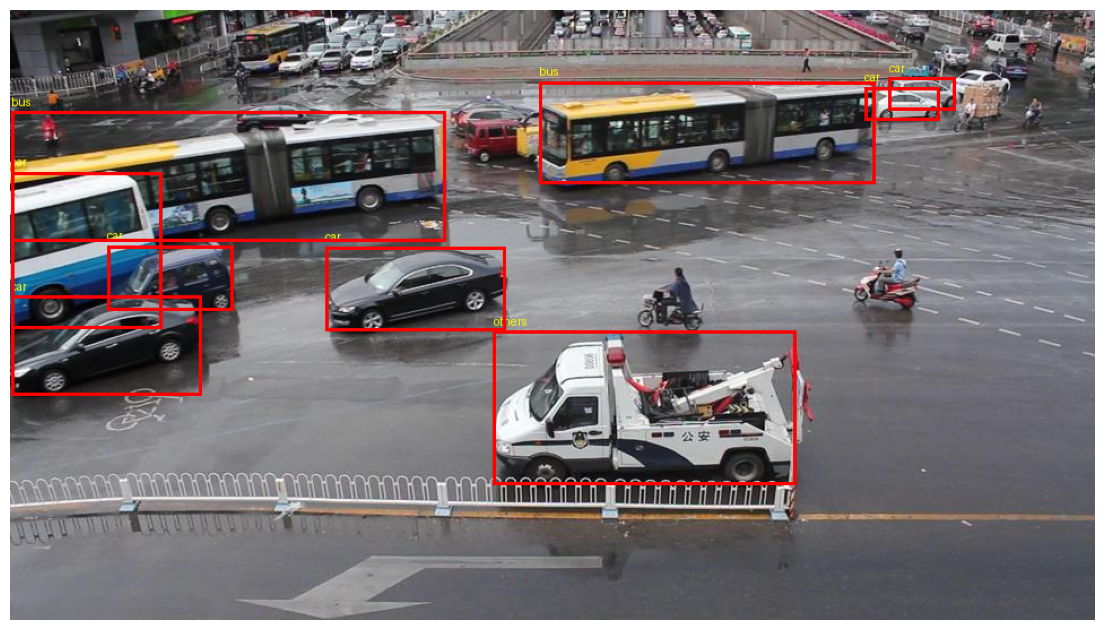

In [5]:

from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# Select one annotated sequence
xml_path = next(
    p for p, name in annotation_sequences
    if name and (IMAGE_ROOT / name).is_dir()
)

xml_root = ET.parse(xml_path).getroot()
sequence_name = xml_root.get("name")

# Select the first annotated frame
frame = xml_root.find("frame")
frame_number = int(frame.get("num"))

image_path = (
    IMAGE_ROOT / sequence_name / f"img{frame_number:05d}.jpg"
)

print("Sequence:", sequence_name)
print("Frame number:", frame_number)
print("Image path:", image_path)

if not image_path.exists():
    print("Expected image not found.")
    print("Available images:",
          list((IMAGE_ROOT / sequence_name).glob("*.jpg"))[:5])
else:
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    target_list = frame.find("target_list")
    targets = (
        target_list.findall("target")
        if target_list is not None else []
    )

    print("Image dimensions:", image.size)
    print("Vehicles annotated in this frame:", len(targets))

    for target in targets:
        box = target.find("box")
        attribute = target.find("attribute")

        if box is None:
            continue

        x = float(box.get("left"))
        y = float(box.get("top"))
        w = float(box.get("width"))
        h = float(box.get("height"))

        label = (
            attribute.get("vehicle_type", "vehicle")
            if attribute is not None else "vehicle"
        )

        draw.rectangle(
            [x, y, x + w, y + h],
            outline="red",
            width=3
        )
        draw.text((x, max(0, y - 15)), label, fill="yellow")

    plt.figure(figsize=(14, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

TRAINING DATA SUMMARY
---------------------
Training XML sequences: 60
Annotated frames: 82085
Vehicle annotations: 598281
Vehicle types: {'car': 503853, 'van': 57051, 'others': 3726, 'bus': 33651}

Training preview: MVI_20011 frame 1


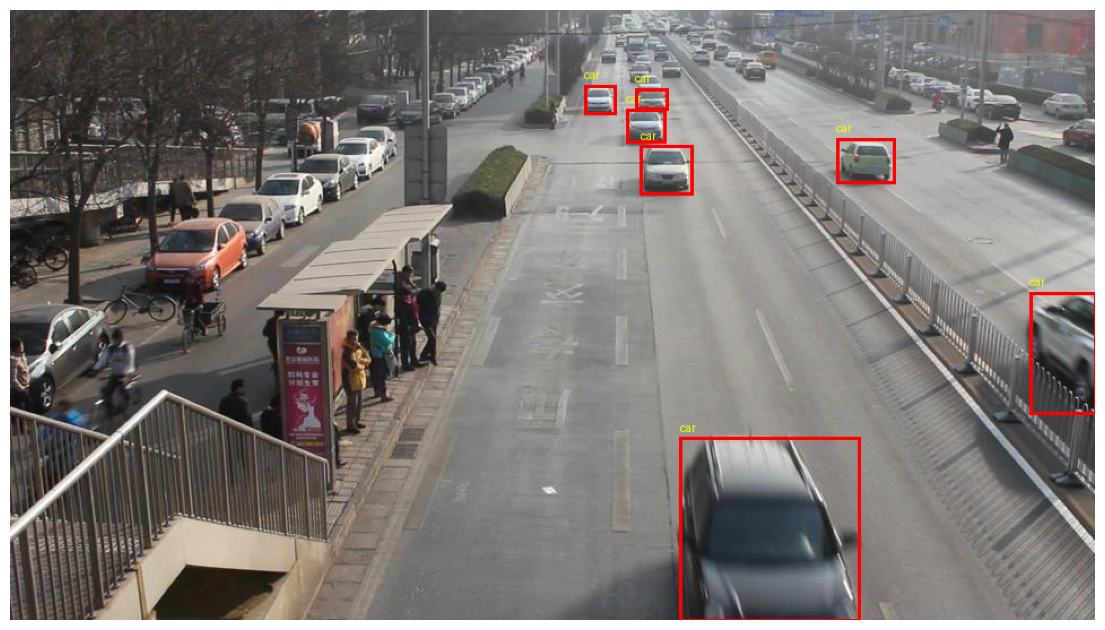

In [6]:

from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

ROOT = Path(DATASET_PATH)
IMAGE_ROOT = ROOT / "DETRAC-Images" / "DETRAC-Images"
TRAIN_XML_ROOT = (
    ROOT / "DETRAC-Train-Annotations-XML"
         / "DETRAC-Train-Annotations-XML"
)

train_xmls = sorted(TRAIN_XML_ROOT.glob("*.xml"))

if not train_xmls:
    raise FileNotFoundError(
        f"No training XML files found at {TRAIN_XML_ROOT}"
    )

class_counts = Counter()
frame_count = 0
target_count = 0
preview = None

for xml_path in train_xmls:
    tree = ET.parse(xml_path)
    sequence = tree.getroot()
    sequence_name = sequence.get("name")
    image_dir = IMAGE_ROOT / sequence_name

    for frame in sequence.findall(".//frame"):
        frame_count += 1
        targets = frame.findall(".//target")
        target_count += len(targets)

        for target in targets:
            attribute = target.find("attribute")
            vehicle_type = (
                attribute.get("vehicle_type", "unknown").lower()
                if attribute is not None else "unknown"
            )
            class_counts[vehicle_type] += 1

        # Find the first frame with labels and a matching image
        if preview is None and targets:
            frame_num = int(frame.get("num"))
            image_path = image_dir / f"img{frame_num:05d}.jpg"

            if image_path.exists():
                preview = (image_path, targets, sequence_name, frame_num)

print("TRAINING DATA SUMMARY")
print("---------------------")
print("Training XML sequences:", len(train_xmls))
print("Annotated frames:", frame_count)
print("Vehicle annotations:", target_count)
print("Vehicle types:", dict(class_counts))

if preview is None:
    print("No matching labeled training image found.")
else:
    image_path, targets, seq_name, frame_num = preview
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    for target in targets:
        box = target.find("box")
        attr = target.find("attribute")

        if box is None:
            continue

        x = float(box.get("left"))
        y = float(box.get("top"))
        w = float(box.get("width"))
        h = float(box.get("height"))

        label = (
            attr.get("vehicle_type", "vehicle")
            if attr is not None else "vehicle"
        )

        draw.rectangle(
            [x, y, x + w, y + h],
            outline="red",
            width=3
        )
        draw.text((x, max(0, y - 15)), label, fill="yellow")

    print("\nTraining preview:", seq_name, "frame", frame_num)
    plt.figure(figsize=(14, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.show()


PROJECT_DIR is not set; preview displayed but not saved.


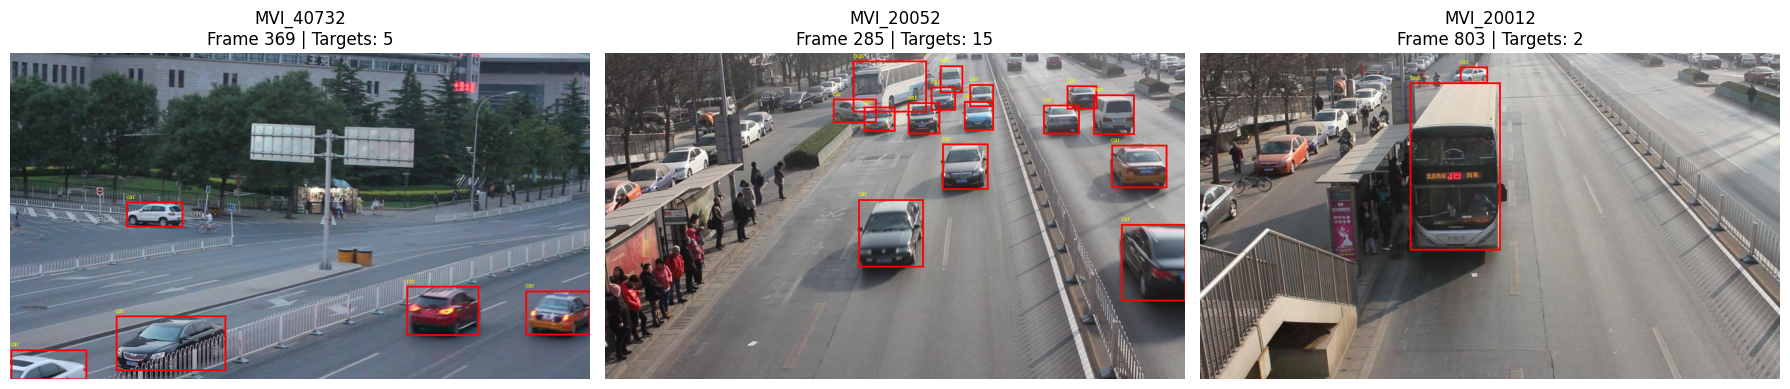

In [7]:

from pathlib import Path
import random
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

random.seed(42)

ROOT = Path(DATASET_PATH)
IMAGE_ROOT = ROOT / "DETRAC-Images" / "DETRAC-Images"
TRAIN_XML_ROOT = (
    ROOT / "DETRAC-Train-Annotations-XML"
         / "DETRAC-Train-Annotations-XML"
)

train_xmls = sorted(TRAIN_XML_ROOT.glob("*.xml"))
selected_xmls = random.sample(train_xmls, min(3, len(train_xmls)))

fig, axes = plt.subplots(1, len(selected_xmls), figsize=(18, 6))

if len(selected_xmls) == 1:
    axes = [axes]

preview_files = []

for ax, xml_path in zip(axes, selected_xmls):
    sequence = ET.parse(xml_path).getroot()
    sequence_name = sequence.get("name")
    frames = sequence.findall(".//frame")

    candidates = [
        frame for frame in frames
        if frame.findall(".//target")
    ]

    chosen_frame = None
    image_path = None

    random.shuffle(candidates)

    for frame in candidates:
        number = int(frame.get("num"))
        candidate_path = (
            IMAGE_ROOT / sequence_name / f"img{number:05d}.jpg"
        )
        if candidate_path.exists():
            chosen_frame = frame
            image_path = candidate_path
            break

    if chosen_frame is None:
        ax.set_title(f"{sequence_name}: no matching frame")
        ax.axis("off")
        continue

    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    targets = chosen_frame.findall(".//target")

    for target in targets:
        box = target.find("box")
        if box is None:
            continue

        x = float(box.get("left"))
        y = float(box.get("top"))
        w = float(box.get("width"))
        h = float(box.get("height"))

        attr = target.find("attribute")
        label = (
            attr.get("vehicle_type", "vehicle")
            if attr is not None else "vehicle"
        )

        draw.rectangle(
            [x, y, x + w, y + h],
            outline="red",
            width=3
        )
        draw.text((x, max(0, y - 15)), label, fill="yellow")

    preview_files.append(image_path)
    ax.imshow(image)
    ax.set_title(
        f"{sequence_name}\nFrame {chosen_frame.get('num')} "
        f"| Targets: {len(targets)}"
    )
    ax.axis("off")

plt.tight_layout()

# Save the visualization permanently to Google Drive, if mounted
try:
    from pathlib import Path
    output_dir = Path(PROJECT_DIR) / "outputs"
    output_dir.mkdir(parents=True, exist_ok=True)
    preview_path = output_dir / "training_annotation_preview.png"
    fig.savefig(preview_path, dpi=150, bbox_inches="tight")
    print("Saved preview:", preview_path)
except NameError:
    print("PROJECT_DIR is not set; preview displayed but not saved.")

plt.show()

In [4]:

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)

for folder in ["checkpoints", "outputs", "metrics", "configs"]:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Drive storage ready!")


Mounted at /content/drive
Project directory: /content/drive/MyDrive/VehicleDetectionProject
Drive storage ready!


In [9]:
preview_path = PROJECT_DIR / "outputs" / "training_annotation_preview.png"

if "fig" in globals():
    fig.savefig(preview_path, dpi=150, bbox_inches="tight")
    print("Preview saved successfully:", preview_path)
else:
    print("The previous figure is no longer in memory.")
    print("Rerun the training annotation visualization cell.")

Preview saved successfully: /content/drive/MyDrive/VehicleDetectionProject/outputs/training_annotation_preview.png


In [10]:

from pathlib import Path
import xml.etree.ElementTree as ET
import random
import json

ROOT = Path(DATASET_PATH)
IMAGE_ROOT = ROOT / "DETRAC-Images" / "DETRAC-Images"

TRAIN_XML_ROOT = (
    ROOT / "DETRAC-Train-Annotations-XML"
    / "DETRAC-Train-Annotations-XML"
)
TEST_XML_ROOT = (
    ROOT / "DETRAC-Test-Annotations-XML"
    / "DETRAC-Test-Annotations-XML"
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
CONFIG_DIR = PROJECT_DIR / "configs"
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

def read_sequence_names(folder):
    names = []
    for xml_path in sorted(folder.glob("*.xml")):
        name = ET.parse(xml_path).getroot().get("name")
        if name:
            names.append(name)
    return sorted(set(names))

train_all = read_sequence_names(TRAIN_XML_ROOT)
test_all = read_sequence_names(TEST_XML_ROOT)

# Verify each sequence has an image directory
missing_train = [
    s for s in train_all if not (IMAGE_ROOT / s).is_dir()
]
missing_test = [
    s for s in test_all if not (IMAGE_ROOT / s).is_dir()
]

train_all = [s for s in train_all if (IMAGE_ROOT / s).is_dir()]
test_all = [s for s in test_all if (IMAGE_ROOT / s).is_dir()]

overlap = set(train_all) & set(test_all)
if overlap:
    raise ValueError(f"Train/test sequence overlap: {sorted(overlap)}")

# Reserve 20% of the training sequences for validation
rng = random.Random(42)
shuffled = train_all.copy()
rng.shuffle(shuffled)

val_count = max(1, round(len(shuffled) * 0.20))
val_sequences = sorted(shuffled[:val_count])
train_sequences = sorted(shuffled[val_count:])
test_sequences = sorted(test_all)

splits = {
    "seed": 42,
    "method": "sequence-level split",
    "train": train_sequences,
    "validation": val_sequences,
    "test": test_sequences,
}

for name, sequences in [
    ("train_sequences.txt", train_sequences),
    ("val_sequences.txt", val_sequences),
    ("test_sequences.txt", test_sequences),
]:
    (CONFIG_DIR / name).write_text(
        "\n".join(sequences) + "\n"
    )

manifest = CONFIG_DIR / "split_manifest.json"
manifest.write_text(json.dumps(splits, indent=2))

print("SEQUENCE SPLIT SUMMARY")
print("-----------------------")
print("Training sequences:", len(train_sequences))
print("Validation sequences:", len(val_sequences))
print("Test sequences:", len(test_sequences))
print("Missing training image folders:", len(missing_train))
print("Missing test image folders:", len(missing_test))
print("Sequence overlap:", len(overlap))
print("Saved manifest:", manifest)


SEQUENCE SPLIT SUMMARY
-----------------------
Training sequences: 48
Validation sequences: 12
Test sequences: 40
Missing training image folders: 0
Missing test image folders: 0
Sequence overlap: 0
Saved manifest: /content/drive/MyDrive/VehicleDetectionProject/configs/split_manifest.json


In [11]:
# Convert XML annotations to COCO JSON
from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET
import json

ROOT = Path(DATASET_PATH)
IMAGE_ROOT = ROOT / "DETRAC-Images" / "DETRAC-Images"

TRAIN_XML_ROOT = (
    ROOT / "DETRAC-Train-Annotations-XML"
    / "DETRAC-Train-Annotations-XML"
)
TEST_XML_ROOT = (
    ROOT / "DETRAC-Test-Annotations-XML"
    / "DETRAC-Test-Annotations-XML"
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
ANNOTATION_DIR = PROJECT_DIR / "annotations"
ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)

with open(PROJECT_DIR / "configs" / "split_manifest.json") as f:
    splits = json.load(f)

# Sample every 10th frame
FRAME_STEP = 10
WIDTH, HEIGHT = 960, 540

CLASS_TO_ID = {
    "car": 1,
    "van": 2,
    "bus": 3,
    "others": 4,
}

# Match XML files to their sequence names
xml_by_sequence = {}

for folder in [TRAIN_XML_ROOT, TEST_XML_ROOT]:
    for path in folder.glob("*.xml"):
        name = ET.parse(path).getroot().get("name")
        if name:
            xml_by_sequence[name] = path

def build_coco(sequence_names, split_name):
    data = {
        "info": {
            "description": "UA-DETRAC vehicle detection",
            "split": split_name,
            "frame_step": FRAME_STEP,
        },
        "licenses": [],
        "images": [],
        "annotations": [],
        "categories": [
            {"id": cid, "name": name}
            for name, cid in CLASS_TO_ID.items()
        ],
    }

    class_counts = Counter()
    missing_images = 0
    missing_xml = []
    unknown_classes = Counter()

    for sequence_name in sequence_names:
        xml_path = xml_by_sequence.get(sequence_name)

        if xml_path is None:
            missing_xml.append(sequence_name)
            continue

        sequence = ET.parse(xml_path).getroot()

        for frame in sequence.findall("./frame"):
            frame_number = int(frame.get("num", "0"))

            if frame_number < 1:
                continue

            if (frame_number - 1) % FRAME_STEP != 0:
                continue

            image_name = f"img{frame_number:05d}.jpg"
            image_path = IMAGE_ROOT / sequence_name / image_name

            if not image_path.is_file():
                missing_images += 1
                continue

            image_id = len(data["images"]) + 1

            data["images"].append({
                "id": image_id,
                "file_name": f"{sequence_name}/{image_name}",
                "width": WIDTH,
                "height": HEIGHT,
            })

            target_list = frame.find("target_list")
            targets = (
                target_list.findall("target")
                if target_list is not None else []
            )

            for target in targets:
                box = target.find("box")
                attr = target.find("attribute")

                if box is None or attr is None:
                    continue

                label = attr.get(
                    "vehicle_type", "unknown"
                ).strip().lower()

                if label not in CLASS_TO_ID:
                    unknown_classes[label] += 1
                    continue

                try:
                    x = float(box.get("left"))
                    y = float(box.get("top"))
                    w = float(box.get("width"))
                    h = float(box.get("height"))
                except (TypeError, ValueError):
                    continue

                # Clip boxes to image boundaries
                x1 = max(0.0, min(x, WIDTH))
                y1 = max(0.0, min(y, HEIGHT))
                x2 = max(0.0, min(x + w, WIDTH))
                y2 = max(0.0, min(y + h, HEIGHT))

                bw, bh = x2 - x1, y2 - y1

                if bw <= 0 or bh <= 0:
                    continue

                data["annotations"].append({
                    "id": len(data["annotations"]) + 1,
                    "image_id": image_id,
                    "category_id": CLASS_TO_ID[label],
                    "bbox": [x1, y1, bw, bh],
                    "area": bw * bh,
                    "iscrowd": 0,
                })

                class_counts[label] += 1

    output_path = ANNOTATION_DIR / f"{split_name}.json"
    output_path.write_text(json.dumps(data))

    print(f"\n{split_name.upper()}")
    print("Images:", len(data["images"]))
    print("Bounding boxes:", len(data["annotations"]))
    print("Class counts:", dict(class_counts))
    print("Missing image files:", missing_images)
    print("Missing XML sequences:", missing_xml)
    print("Unknown classes:", dict(unknown_classes))
    print("Saved:", output_path)

    return data

train_data = build_coco(splits["train"], "train")
val_data = build_coco(splits["validation"], "val")
test_data = build_coco(splits["test"], "test")

print("\nAnnotation conversion complete.")



TRAIN
Images: 6815
Bounding boxes: 51341
Class counts: {'car': 43143, 'van': 4721, 'others': 314, 'bus': 3163}
Missing image files: 0
Missing XML sequences: []
Unknown classes: {}
Saved: /content/drive/MyDrive/VehicleDetectionProject/annotations/train.json

VAL
Images: 1417
Bounding boxes: 10745
Class counts: {'car': 9189, 'van': 1238, 'others': 71, 'bus': 247}
Missing image files: 0
Missing XML sequences: []
Unknown classes: {}
Saved: /content/drive/MyDrive/VehicleDetectionProject/annotations/val.json

TEST
Images: 5625
Bounding boxes: 68401
Class counts: {'car': 55557, 'van': 3891, 'bus': 7252, 'others': 1701}
Missing image files: 0
Missing XML sequences: []
Unknown classes: {}
Saved: /content/drive/MyDrive/VehicleDetectionProject/annotations/test.json

Annotation conversion complete.



TRAIN
Images: 6815
Annotations: 51341
Missing images: 0
Invalid bounding boxes: 0


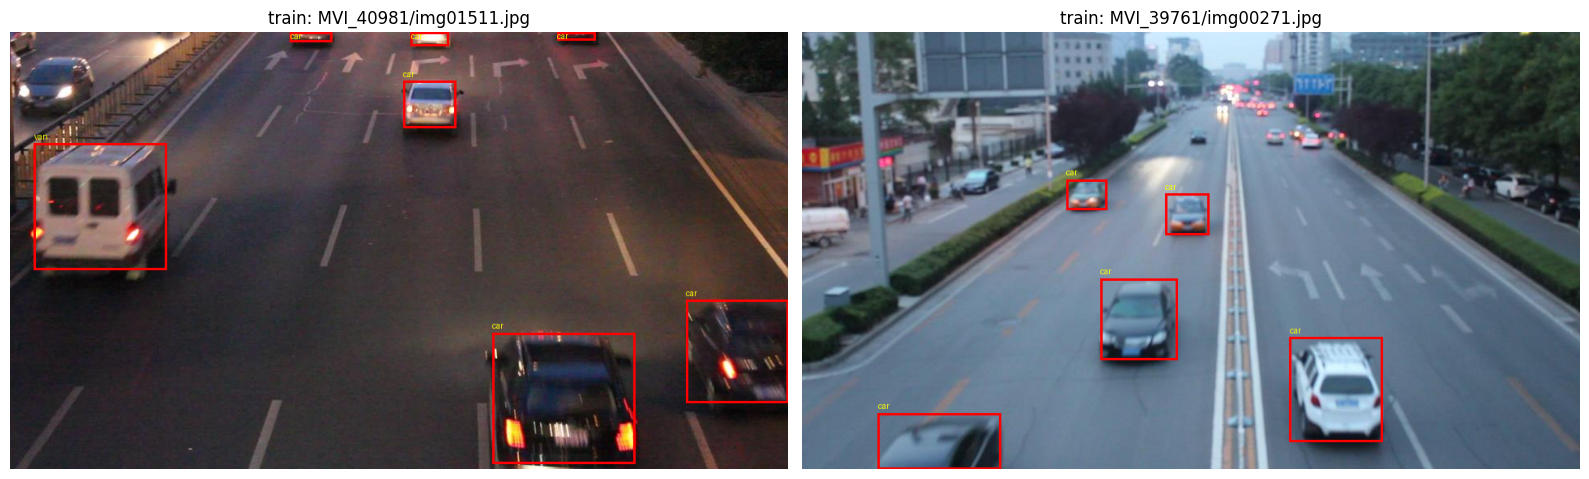

Preview saved: /content/drive/MyDrive/VehicleDetectionProject/outputs/train_json_validation.png

VAL
Images: 1417
Annotations: 10745
Missing images: 0
Invalid bounding boxes: 0


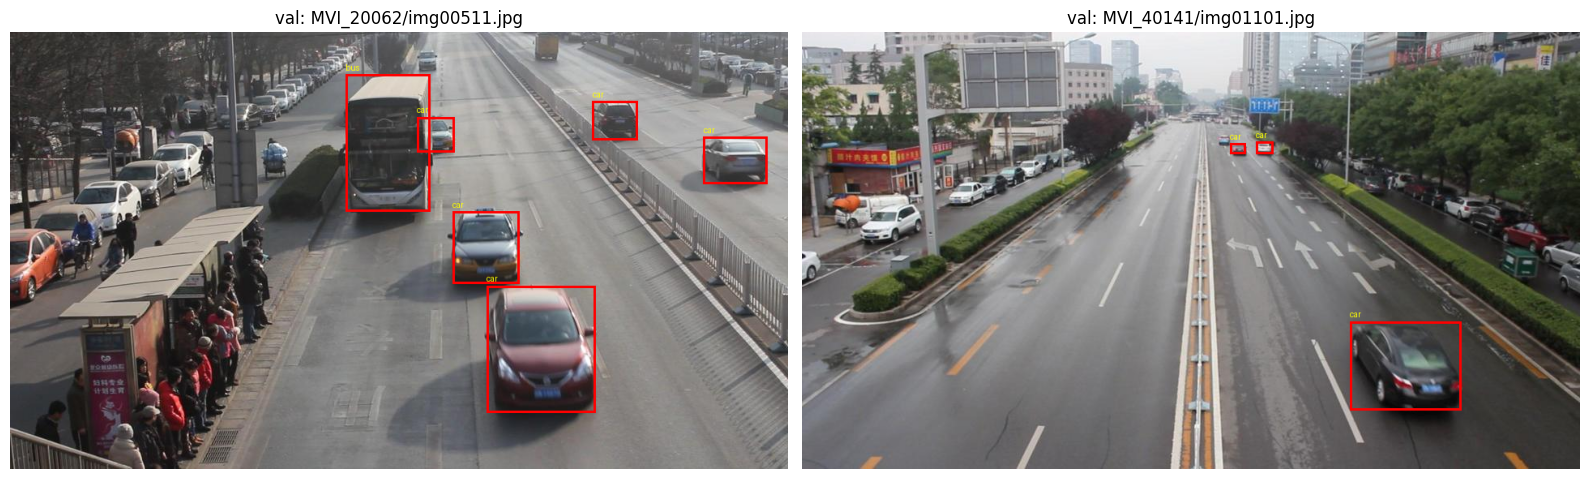

Preview saved: /content/drive/MyDrive/VehicleDetectionProject/outputs/val_json_validation.png

TEST
Images: 5625
Annotations: 68401
Missing images: 0
Invalid bounding boxes: 0


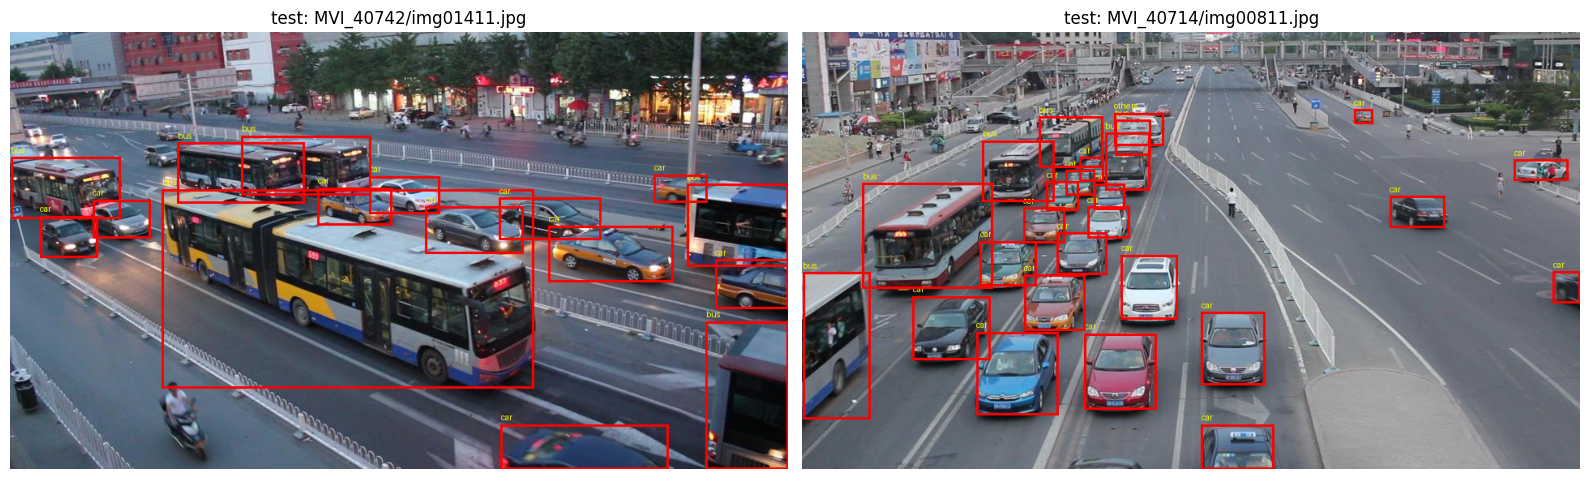

Preview saved: /content/drive/MyDrive/VehicleDetectionProject/outputs/test_json_validation.png


In [13]:
from pathlib import Path
from collections import defaultdict
import json
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
IMAGE_ROOT = (
    Path(DATASET_PATH)
    / "DETRAC-Images"
    / "DETRAC-Images"
)
ANNOTATION_DIR = PROJECT_DIR / "annotations"

random.seed(42)

datasets = {}
for split in ["train", "val", "test"]:
    with open(ANNOTATION_DIR / f"{split}.json") as f:
        datasets[split] = json.load(f)

def validate_and_preview(split, number_of_samples=2):
    data = datasets[split]

    images = data["images"]
    annotations = data["annotations"]
    categories = {
        c["id"]: c["name"] for c in data["categories"]
    }

    anns_by_image = defaultdict(list)
    for ann in annotations:
        anns_by_image[ann["image_id"]].append(ann)

    image_by_id = {img["id"]: img for img in images}

    missing_images = 0
    invalid_boxes = 0

    for img in images:
        path = IMAGE_ROOT / img["file_name"]
        if not path.is_file():
            missing_images += 1

    for ann in annotations:
        img = image_by_id.get(ann["image_id"])
        if img is None:
            invalid_boxes += 1
            continue

        x, y, w, h = ann["bbox"]

        if (
            w <= 0 or h <= 0 or
            x < 0 or y < 0 or
            x + w > img["width"] + 0.01 or
            y + h > img["height"] + 0.01
        ):
            invalid_boxes += 1

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Annotations:", len(annotations))
    print("Missing images:", missing_images)
    print("Invalid bounding boxes:", invalid_boxes)

    candidates = [
        img for img in images
        if anns_by_image.get(img["id"])
        and (IMAGE_ROOT / img["file_name"]).is_file()
    ]

    selected = random.sample(
        candidates, min(number_of_samples, len(candidates))
    )

    fig, axes = plt.subplots(
        1, len(selected),
        figsize=(8 * len(selected), 5)
    )

    if len(selected) == 1:
        axes = [axes]

    for ax, img in zip(axes, selected):
        path = IMAGE_ROOT / img["file_name"]
        picture = Image.open(path).convert("RGB")
        draw = ImageDraw.Draw(picture)

        for ann in anns_by_image[img["id"]]:
            x, y, w, h = ann["bbox"]
            label = categories[ann["category_id"]]

            draw.rectangle(
                [x, y, x + w, y + h],
                outline="red",
                width=3
            )
            draw.text(
                (x, max(0, y - 15)),
                label,
                fill="yellow"
            )

        ax.imshow(picture)
        ax.set_title(f"{split}: {img['file_name']}")
        ax.axis("off")

    plt.tight_layout()

    output_path = (
        PROJECT_DIR / "outputs" /
        f"{split}_json_validation.png"
    )
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()

    print("Preview saved:", output_path)

for split in ["train", "val", "test"]:
    validate_and_preview(split)


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable GPU: Runtime > Change runtime type > GPU")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [5]:
import json
import numpy as np
import torch
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader

ROOT = Path(DATASET_PATH)
IMAGE_ROOT = ROOT / "DETRAC-Images" / "DETRAC-Images"
PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)

INPUT_W, INPUT_H = 512, 288
OUTPUT_W, OUTPUT_H = INPUT_W // 4, INPUT_H // 4
NUM_CLASSES = 4
MAX_OBJECTS = 100

CLASS_NAMES = ["car", "van", "bus", "others"]

def draw_gaussian(heatmap, cx, cy, radius=2):
    h, w = heatmap.shape
    sigma = (2 * radius + 1) / 6.0

    x1, x2 = max(0, cx-radius), min(w-1, cx+radius)
    y1, y2 = max(0, cy-radius), min(h-1, cy+radius)

    if x1 > x2 or y1 > y2:
        return

    xs = np.arange(x1, x2+1)
    ys = np.arange(y1, y2+1)
    xx, yy = np.meshgrid(xs, ys)

    gaussian = np.exp(
        -((xx-cx)**2 + (yy-cy)**2) / (2*sigma*sigma)
    ).astype(np.float32)

    np.maximum(
        heatmap[y1:y2+1, x1:x2+1],
        gaussian,
        out=heatmap[y1:y2+1, x1:x2+1]
    )


class DETRACDataset(Dataset):
    def __init__(self, json_path):
        with open(json_path) as f:
            self.data = json.load(f)

        self.images = self.data["images"]
        self.annotations = {}

        for ann in self.data["annotations"]:
            self.annotations.setdefault(
                ann["image_id"], []
            ).append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        info = self.images[idx]
        path = IMAGE_ROOT / info["file_name"]

        image = Image.open(path).convert("RGB")
        image = image.resize(
            (INPUT_W, INPUT_H), Image.Resampling.BILINEAR
        )

        array = np.asarray(image, dtype=np.float32) / 255.0
        image_tensor = torch.from_numpy(
            array.copy()
        ).permute(2, 0, 1)

        mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
        std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
        image_tensor = (image_tensor - mean) / std

        hm = np.zeros(
            (NUM_CLASSES, OUTPUT_H, OUTPUT_W),
            dtype=np.float32
        )
        wh = np.zeros((MAX_OBJECTS, 2), dtype=np.float32)
        off = np.zeros((MAX_OBJECTS, 2), dtype=np.float32)
        ind = np.zeros(MAX_OBJECTS, dtype=np.int64)
        mask = np.zeros(MAX_OBJECTS, dtype=np.uint8)

        sx = INPUT_W / info["width"]
        sy = INPUT_H / info["height"]
        obj_idx = 0

        for ann in self.annotations.get(info["id"], []):
            if obj_idx >= MAX_OBJECTS:
                break

            x, y, bw, bh = ann["bbox"]

            # Scale box into the resized image, then stride-4 map
            x *= sx
            y *= sy
            bw *= sx
            bh *= sy

            cx = (x + bw / 2) / 4
            cy = (y + bh / 2) / 4

            ix, iy = int(cx), int(cy)
            cls = int(ann["category_id"]) - 1

            if not (
                0 <= cls < NUM_CLASSES
                and 0 <= ix < OUTPUT_W
                and 0 <= iy < OUTPUT_H
                and bw > 0 and bh > 0
            ):
                continue

            draw_gaussian(hm[cls], ix, iy)

            wh[obj_idx] = [bw / 4, bh / 4]
            off[obj_idx] = [cx - ix, cy - iy]
            ind[obj_idx] = iy * OUTPUT_W + ix
            mask[obj_idx] = 1
            obj_idx += 1

        return (
            image_tensor,
            torch.from_numpy(hm),
            torch.from_numpy(wh),
            torch.from_numpy(off),
            torch.from_numpy(ind),
            torch.from_numpy(mask)
        )


train_json = PROJECT_DIR / "annotations" / "train.json"
val_json = PROJECT_DIR / "annotations" / "val.json"

train_ds = DETRACDataset(train_json)
val_ds = DETRACDataset(val_json)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
batch_size = 8 if device.type == "cuda" else 2

train_loader = DataLoader(
    train_ds,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Device:", device)
print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Input:", INPUT_W, "x", INPUT_H)
print("Output map:", OUTPUT_W, "x", OUTPUT_H)

batch = next(iter(train_loader))
print("Image batch:", batch[0].shape)
print("Heatmap batch:", batch[1].shape)
print("Batch preparation successful.")


Device: cuda
Training images: 6815
Validation images: 1417
Input: 512 x 288
Output map: 128 x 72
Image batch: torch.Size([8, 3, 288, 512])
Heatmap batch: torch.Size([8, 4, 72, 128])
Batch preparation successful.


In [6]:

import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

class CenterNetBaseline(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        backbone = resnet18(weights=ResNet18_Weights.DEFAULT)

        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        def make_head(outputs):
            return nn.Sequential(
                nn.Conv2d(64, 64, 3, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(64, outputs, 1)
            )

        self.hm_head = make_head(num_classes)
        self.wh_head = make_head(2)
        self.off_head = make_head(2)

        nn.init.constant_(self.hm_head[-1].bias, -2.19)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.decoder(x)

        return {
            "hm": self.hm_head(x),
            "wh": self.wh_head(x),
            "off": self.off_head(x)
        }


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CenterNetBaseline(num_classes=4).to(device)

# Test with one actual batch
images = next(iter(train_loader))[0].to(device)

model.eval()
with torch.no_grad():
    predictions = model(images)

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

for name, prediction in predictions.items():
    print(f"{name}: {tuple(prediction.shape)}")

assert predictions["hm"].shape == (len(images), 4, 72, 128)
assert predictions["wh"].shape == (len(images), 2, 72, 128)
assert predictions["off"].shape == (len(images), 2, 72, 128)

print("\nCenterNet baseline architecture verified!")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s]


Device: cuda
GPU: Tesla T4
hm: (8, 4, 72, 128)
wh: (8, 2, 72, 128)
off: (8, 2, 72, 128)

CenterNet baseline architecture verified!


In [7]:

import torch
import torch.nn.functional as F

def center_focal_loss(logits, target):
    pred = torch.sigmoid(logits.float()).clamp(1e-6, 1 - 1e-6)

    positive = (target == 1).float()
    negative = (target < 1).float()
    negative_weights = (1 - target) ** 4

    positive_loss = (
        torch.log(pred) * (1 - pred) ** 2 * positive
    )
    negative_loss = (
        torch.log(1 - pred)
        * pred ** 2
        * negative_weights
        * negative
    )

    num_positive = positive.sum()

    if num_positive.item() > 0:
        return -(positive_loss.sum() + negative_loss.sum()) / num_positive

    return -negative_loss.sum()


def gather_features(feature_map, indices):
    batch_size, channels, height, width = feature_map.shape

    feature_map = feature_map.permute(0, 2, 3, 1).contiguous()
    feature_map = feature_map.view(
        batch_size, height * width, channels
    )

    indices = indices.unsqueeze(-1).expand(
        -1, -1, channels
    )
    return feature_map.gather(1, indices)


def compute_centernet_loss(outputs, targets):
    _, heatmap, wh, offset, indices, mask = targets

    heatmap = heatmap.to(device).float()
    wh = wh.to(device).float()
    offset = offset.to(device).float()
    indices = indices.to(device).long()
    mask = mask.to(device).float().unsqueeze(-1)

    hm_loss = center_focal_loss(outputs["hm"], heatmap)

    pred_wh = gather_features(outputs["wh"], indices).float()
    pred_offset = gather_features(outputs["off"], indices).float()

    wh_loss = (
        F.l1_loss(pred_wh * mask, wh * mask, reduction="sum")
        / mask.sum().clamp(min=1)
    )

    off_loss = (
        F.l1_loss(
            pred_offset * mask,
            offset * mask,
            reduction="sum"
        )
        / mask.sum().clamp(min=1)
    )

    total_loss = hm_loss + 0.1 * wh_loss + off_loss

    return {
        "total": total_loss,
        "heatmap": hm_loss,
        "width_height": wh_loss,
        "offset": off_loss,
    }


# Smoke test: check that all losses and gradients work
model.train()
device = next(model.parameters()).device

sample = next(iter(train_loader))
sample = tuple(t.to(device) for t in sample)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-4, weight_decay=1e-4
)

optimizer.zero_grad(set_to_none=True)

predictions = model(sample[0])
losses = compute_centernet_loss(predictions, sample)

assert torch.isfinite(losses["total"]), "Loss is not finite!"

losses["total"].backward()

print("Loss function test passed!")
for name, value in losses.items():
    print(f"{name}: {value.item():.4f}")

print("Gradient computed:", any(
    p.grad is not None for p in model.parameters()
))

optimizer.zero_grad(set_to_none=True)


Loss function test passed!
total: 10.6398
heatmap: 7.9590
width_height: 16.8645
offset: 0.9944
Gradient computed: True


In [9]:
from pathlib import Path
import csv
import torch
from tqdm.auto import tqdm

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
METRICS_DIR = PROJECT_DIR / "metrics"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

LATEST_PATH = CHECKPOINT_DIR / "centernet_latest.pth"
BEST_PATH = CHECKPOINT_DIR / "centernet_best.pth"
HISTORY_PATH = METRICS_DIR / "training_history.csv"

EPOCHS = 12
USE_AMP = (device.type == "cuda")

optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-4, weight_decay=1e-4
)
scaler = torch.amp.GradScaler(
    "cuda", enabled=USE_AMP
)

start_epoch = 0
history = []
best_val_loss = float("inf")

# Resume from Drive if a previous checkpoint exists
if LATEST_PATH.exists():
    checkpoint = torch.load(
        LATEST_PATH,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if "scaler_state_dict" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler_state_dict"])

    start_epoch = checkpoint["epoch_completed"]
    history = checkpoint.get("history", [])
    best_val_loss = checkpoint.get(
        "best_val_loss", float("inf")
    )

    print("Resuming from completed epoch:", start_epoch)
else:
    print("Starting fresh training.")

if start_epoch >= EPOCHS:
    print(
        f"{EPOCHS} epochs already completed. "
        "Increase EPOCHS to continue training."
    )

for epoch in range(start_epoch, EPOCHS):
    # Training phase
    model.train()
    train_sums = {"total": 0.0, "heatmap": 0.0,
                  "width_height": 0.0, "offset": 0.0}

    progress = tqdm(
        train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch in progress:
        batch = tuple(t.to(device, non_blocking=True) for t in batch)
        images = batch[0]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type, enabled=USE_AMP
        ):
            predictions = model(images)

        losses = compute_centernet_loss(predictions, batch)

        if not torch.isfinite(losses["total"]):
            raise RuntimeError(
                "Non-finite training loss; stopping to avoid "
                "saving corrupted training state."
            )

        scaler.scale(losses["total"]).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=10.0
        )

        scaler.step(optimizer)
        scaler.update()

        for key in train_sums:
            train_sums[key] += losses[key].item()

        progress.set_postfix(loss=f"{losses['total'].item():.3f}")

    train_avg = {
        key: value / max(1, len(train_loader))
        for key, value in train_sums.items()
    }

    # Validation phase
    model.eval()
    val_sums = {key: 0.0 for key in train_sums}

    with torch.no_grad():
        for batch in tqdm(val_loader, desc="Validation"):
            batch = tuple(
                t.to(device, non_blocking=True) for t in batch
            )

            with torch.autocast(
                device_type=device.type, enabled=USE_AMP
            ):
                predictions = model(batch[0])

            losses = compute_centernet_loss(predictions, batch)

            for key in val_sums:
                val_sums[key] += losses[key].item()

    val_avg = {
        key: value / max(1, len(val_loader))
        for key, value in val_sums.items()
    }

    row = {
        "epoch": epoch + 1,
        "train_loss": train_avg["total"],
        "train_heatmap_loss": train_avg["heatmap"],
        "train_wh_loss": train_avg["width_height"],
        "train_offset_loss": train_avg["offset"],
        "val_loss": val_avg["total"],
        "val_heatmap_loss": val_avg["heatmap"],
        "val_wh_loss": val_avg["width_height"],
        "val_offset_loss": val_avg["offset"],
    }

    history.append(row)

    if val_avg["total"] < best_val_loss:
        best_val_loss = val_avg["total"]
        torch.save(model.state_dict(), BEST_PATH)

    # Save resumable checkpoint at the end of every epoch
    torch.save({
        "epoch_completed": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "best_val_loss": best_val_loss,
    }, LATEST_PATH)

    with open(HISTORY_PATH, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
        writer.writeheader()
        writer.writerows(history)

    print(f"\nEpoch {epoch + 1} results")
    print(f"Train loss: {train_avg['total']:.4f}")
    print(f"Validation loss: {val_avg['total']:.4f}")
    print("Latest checkpoint:", LATEST_PATH)
    print("Best model:", BEST_PATH)

print("\nTraining run finished.")
print("History:", HISTORY_PATH)

Starting fresh training.


Epoch 1/12:   0%|          | 0/852 [00:00<?, ?it/s]

Validation:   0%|          | 0/178 [00:00<?, ?it/s]


Epoch 1 results
Train loss: 2.0866
Validation loss: 2.0215
Latest checkpoint: /content/drive/MyDrive/VehicleDetectionProject/checkpoints/centernet_latest.pth
Best model: /content/drive/MyDrive/VehicleDetectionProject/checkpoints/centernet_best.pth


Epoch 2/12:   0%|          | 0/852 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/178 [00:00<?, ?it/s]


Epoch 11 results
Train loss: 0.4731
Validation loss: 2.5257
Latest checkpoint: /content/drive/MyDrive/VehicleDetectionProject/checkpoints/centernet_latest.pth
Best model: /content/drive/MyDrive/VehicleDetectionProject/checkpoints/centernet_best.pth


Epoch 12/12:   0%|          | 0/852 [00:00<?, ?it/s]

Validation:   0%|          | 0/178 [00:00<?, ?it/s]


Epoch 12 results
Train loss: 0.4562
Validation loss: 2.4903
Latest checkpoint: /content/drive/MyDrive/VehicleDetectionProject/checkpoints/centernet_latest.pth
Best model: /content/drive/MyDrive/VehicleDetectionProject/checkpoints/centernet_best.pth

Training run finished.
History: /content/drive/MyDrive/VehicleDetectionProject/metrics/training_history.csv


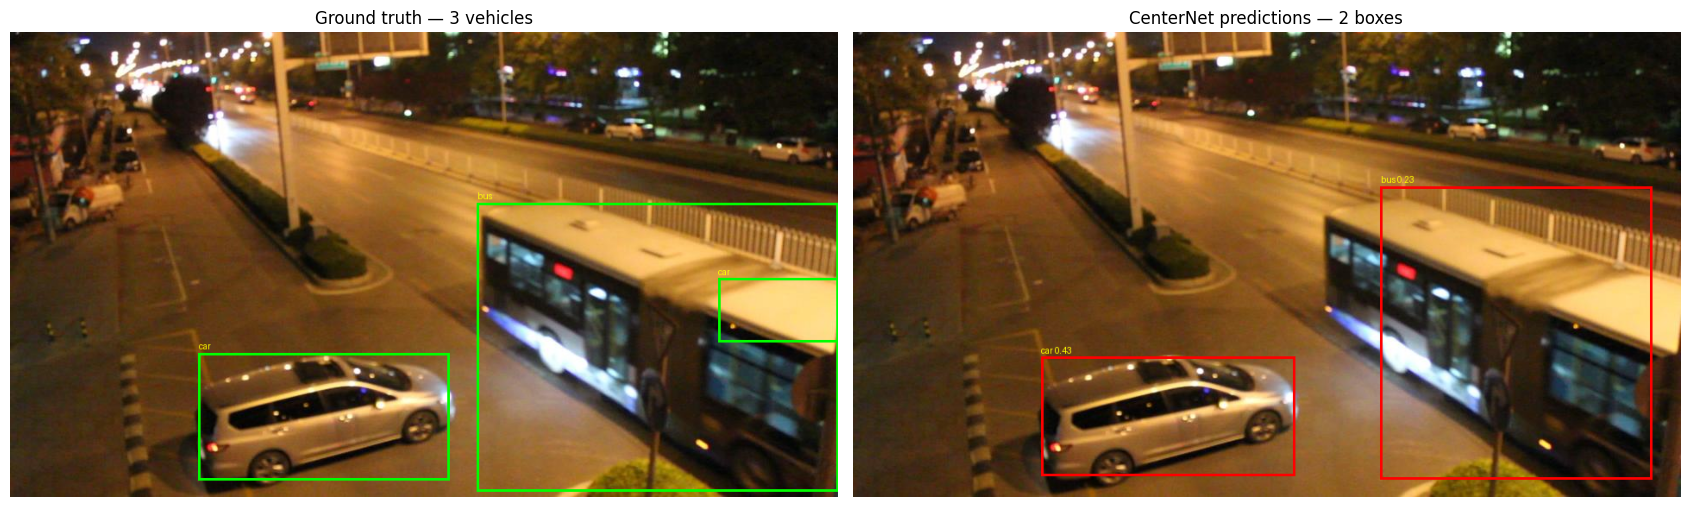

Validation image: MVI_39861/img00061.jpg
Ground-truth boxes: 3
Predicted boxes: 2
Saved: /content/drive/MyDrive/VehicleDetectionProject/outputs/baseline_prediction_preview.png


In [10]:

from pathlib import Path
from collections import defaultdict
import json

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
BEST_PATH = PROJECT_DIR / "checkpoints" / "centernet_best.pth"

ROOT = Path(DATASET_PATH)
IMAGE_ROOT = ROOT / "DETRAC-Images" / "DETRAC-Images"

# Restore the best model, not the final-epoch weights
best_state = torch.load(
    BEST_PATH, map_location=device, weights_only=True
)
model.load_state_dict(best_state)
model.eval()

with open(PROJECT_DIR / "annotations" / "val.json") as f:
    val_json = json.load(f)

categories = {
    item["id"]: item["name"]
    for item in val_json["categories"]
}

anns_by_image = defaultdict(list)
for ann in val_json["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)

# Select a validation image containing several labelled vehicles
candidates = [
    img for img in val_json["images"]
    if len(anns_by_image[img["id"]]) >= 3
]

import random
random.seed(21)
info = random.choice(candidates)

image_path = IMAGE_ROOT / info["file_name"]
original = Image.open(image_path).convert("RGB")

# The model uses the same preprocessing as the dataset
idx = next(
    i for i, row in enumerate(val_ds.images)
    if row["id"] == info["id"]
)
image_tensor = val_ds[idx][0].unsqueeze(0).to(device)

with torch.no_grad():
    outputs = model(image_tensor)

# Decode center heatmaps
heat = outputs["hm"].sigmoid()
local_max = F.max_pool2d(
    heat, kernel_size=3, stride=1, padding=1
)
heat = heat * (heat >= local_max).float()

scores_flat = heat[0].reshape(-1)
k = min(100, scores_flat.numel())
scores, indices = torch.topk(scores_flat, k)

height, width = heat.shape[-2:]
pred_wh = outputs["wh"][0]
pred_off = outputs["off"][0]

pred_img = original.copy()
draw = ImageDraw.Draw(pred_img)

scale_x = info["width"] / INPUT_W
scale_y = info["height"] / INPUT_H

THRESHOLD = 0.20
pred_count = 0

for score, index in zip(scores, indices):
    confidence = score.item()
    if confidence < THRESHOLD:
        continue

    index = index.item()
    cls = index // (height * width)
    cell = index % (height * width)
    y, x = divmod(cell, width)

    offset_x = pred_off[0, y, x].item()
    offset_y = pred_off[1, y, x].item()

    bw = max(1, pred_wh[0, y, x].item() * 4)
    bh = max(1, pred_wh[1, y, x].item() * 4)

    # Convert output-map coordinates to input-image pixels
    cx = (x + offset_x) * 4
    cy = (y + offset_y) * 4

    x1 = max(0, (cx - bw / 2) * scale_x)
    y1 = max(0, (cy - bh / 2) * scale_y)
    x2 = min(info["width"], (cx + bw / 2) * scale_x)
    y2 = min(info["height"], (cy + bh / 2) * scale_y)

    if x2 <= x1 or y2 <= y1:
        continue

    label = categories[cls + 1]
    draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
    draw.text(
        (x1, max(0, y1 - 14)),
        f"{label} {confidence:.2f}",
        fill="yellow"
    )
    pred_count += 1

# Draw ground truth on a separate copy
gt_img = original.copy()
gt_draw = ImageDraw.Draw(gt_img)

for ann in anns_by_image[info["id"]]:
    x, y, bw, bh = ann["bbox"]
    label = categories[ann["category_id"]]
    gt_draw.rectangle(
        [x, y, x + bw, y + bh],
        outline="lime", width=3
    )
    gt_draw.text(
        (x, max(0, y - 14)), label, fill="yellow"
    )

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
axes[0].imshow(gt_img)
axes[0].set_title(
    f"Ground truth — {len(anns_by_image[info['id']])} vehicles"
)
axes[1].imshow(pred_img)
axes[1].set_title(
    f"CenterNet predictions — {pred_count} boxes"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()

output = PROJECT_DIR / "outputs" / "baseline_prediction_preview.png"
output.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output, dpi=150, bbox_inches="tight")
plt.show()

print("Validation image:", info["file_name"])
print("Ground-truth boxes:", len(anns_by_image[info["id"]]))
print("Predicted boxes:", pred_count)
print("Saved:", output)


In [11]:
!pip -q install pycocotools

In [12]:
import json
import torch
import torch.nn.functional as F
from pathlib import Path
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
BEST_PATH = PROJECT_DIR / "checkpoints" / "centernet_best.pth"
VAL_JSON = PROJECT_DIR / "annotations" / "val.json"
DEVICE = next(model.parameters()).device

# Load the best validation-loss checkpoint
model.load_state_dict(torch.load(
    BEST_PATH, map_location=DEVICE, weights_only=True
))
model.eval()

gt = COCO(str(VAL_JSON))
predictions = []
seen = 0
MAX_DETECTIONS = 100
SCORE_THRESHOLD = 0.001

with torch.inference_mode():
    for batch in tqdm(val_loader, desc="Evaluating validation set"):
        images = batch[0].to(DEVICE)
        outputs = model(images)

        # Suppress non-maximum heatmap positions
        heat = outputs["hm"].float().sigmoid()
        peaks = F.max_pool2d(
            heat, kernel_size=3, stride=1, padding=1
        )
        heat = heat * (heat >= peaks)

        batch_size, classes, out_h, out_w = heat.shape

        for b in range(batch_size):
            info = val_ds.images[seen + b]
            flat = heat[b].reshape(-1)
            k = min(MAX_DETECTIONS, flat.numel())
            scores, indices = torch.topk(flat, k)

            pred_wh = outputs["wh"][b].float()
            pred_off = outputs["off"][b].float()

            sx = info["width"] / INPUT_W
            sy = info["height"] / INPUT_H

            for score, index in zip(scores, indices):
                conf = float(score.item())
                if conf < SCORE_THRESHOLD:
                    continue

                index = int(index.item())
                cls = index // (out_h * out_w)
                pos = index % (out_h * out_w)
                y, x = divmod(pos, out_w)

                # Predictions are in feature-map units
                bw = float(pred_wh[0, y, x].item()) * 4
                bh = float(pred_wh[1, y, x].item()) * 4

                # Discard invalid predicted dimensions
                if bw <= 0 or bh <= 0:
                    continue

                cx = (x + float(pred_off[0, y, x].item())) * 4
                cy = (y + float(pred_off[1, y, x].item())) * 4

                x1 = max(0.0, (cx - bw / 2) * sx)
                y1 = max(0.0, (cy - bh / 2) * sy)
                x2 = min(float(info["width"]), (cx + bw / 2) * sx)
                y2 = min(float(info["height"]), (cy + bh / 2) * sy)

                if x2 <= x1 or y2 <= y1:
                    continue

                predictions.append({
                    "image_id": int(info["id"]),
                    "category_id": int(cls + 1),
                    "bbox": [x1, y1, x2 - x1, y2 - y1],
                    "score": conf
                })

        seen += batch_size

print("Images processed:", seen)
print("Valid predicted boxes:", len(predictions))

if not predictions:
    raise RuntimeError("No valid predictions. Inspect the model outputs.")

# Save raw detections for reproducibility
output_path = PROJECT_DIR / "outputs" / "validation_predictions.json"
output_path.parent.mkdir(parents=True, exist_ok=True)
output_path.write_text(json.dumps(predictions))

# COCO object detection metrics
dt = gt.loadRes(predictions)
evaluator = COCOeval(gt, dt, "bbox")
evaluator.evaluate()
evaluator.accumulate()
evaluator.summarize()

stats = evaluator.stats

metrics = {
    "images_evaluated": seen,
    "predicted_boxes": len(predictions),
    "mAP_50_95_percent": round(float(stats[0] * 100), 2),
    "AP_50_percent": round(float(stats[1] * 100), 2),
    "AP_75_percent": round(float(stats[2] * 100), 2),
    "AR_100_percent": round(float(stats[8] * 100), 2),
}

# Per-class AP across IoU 0.50–0.95
precision = evaluator.eval["precision"]
for i, category_id in enumerate(evaluator.params.catIds):
    category = gt.loadCats([category_id])[0]
    values = precision[:, :, i, 0, -1]
    values = values[values > -1]

    metrics[f"AP_{category['name']}_percent"] = (
        round(float(values.mean() * 100), 2)
        if values.size else None
    )

metrics_path = PROJECT_DIR / "metrics" / "baseline_validation_metrics.json"
metrics_path.parent.mkdir(parents=True, exist_ok=True)
metrics_path.write_text(json.dumps(metrics, indent=2))

print("\nBASELINE VALIDATION METRICS")
print(json.dumps(metrics, indent=2))
print("\nPredictions saved:", output_path)
print("Metrics saved:", metrics_path)

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!


Evaluating validation set:   0%|          | 0/178 [00:00<?, ?it/s]

Images processed: 1417
Valid predicted boxes: 141700
Loading and preparing results...
DONE (t=10.52s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=9.42s).
Accumulating evaluation results...
DONE (t=1.53s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.309
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.534
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.314
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.026
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.283
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.445
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.286
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.522
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.533
 Average Recal

In [13]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
BASELINE_PATH = PROJECT_DIR / "checkpoints" / "centernet_best.pth"

# Reuse your previous CBAM, BiFPN, baseline classes if already defined.
class CBAM(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False)
        )
        self.spatial = nn.Conv2d(
            2, 1, kernel_size=7, padding=3, bias=False
        )

    def forward(self, x):
        channel_weight = torch.sigmoid(
            self.mlp(F.adaptive_avg_pool2d(x, 1))
            + self.mlp(F.adaptive_max_pool2d(x, 1))
        )
        x = x * channel_weight

        avg = x.mean(dim=1, keepdim=True)
        maximum = x.max(dim=1, keepdim=True).values
        spatial_weight = torch.sigmoid(
            self.spatial(torch.cat([avg, maximum], dim=1))
        )
        return x * spatial_weight


class ConvBNAct(nn.Sequential):
    def __init__(self, in_channels, out_channels, kernel_size=3):
        super().__init__(
            nn.Conv2d(
                in_channels, out_channels, kernel_size,
                padding=kernel_size // 2, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )


class FastFusion(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.weights = nn.Parameter(torch.ones(n_inputs))

    def forward(self, inputs):
        weights = F.relu(self.weights)
        weights = weights / (weights.sum() + 1e-4)
        return sum(w * x for w, x in zip(weights, inputs))


class BiFPNBlock(nn.Module):
    def __init__(self, channels=64):
        super().__init__()

        self.fuse4 = FastFusion(2)
        self.fuse3 = FastFusion(2)
        self.fuse2 = FastFusion(2)
        self.fuse3_out = FastFusion(3)
        self.fuse4_out = FastFusion(3)
        self.fuse5_out = FastFusion(2)

        self.conv4 = ConvBNAct(channels, channels)
        self.conv3 = ConvBNAct(channels, channels)
        self.conv2 = ConvBNAct(channels, channels)
        self.conv3_out = ConvBNAct(channels, channels)
        self.conv4_out = ConvBNAct(channels, channels)
        self.conv5_out = ConvBNAct(channels, channels)

    @staticmethod
    def resize(x, ref):
        return F.interpolate(
            x, size=ref.shape[-2:], mode="nearest"
        )

    def forward(self, features):
        p2, p3, p4, p5 = features

        p4_td = self.conv4(self.fuse4([
            p4, self.resize(p5, p4)
        ]))
        p3_td = self.conv3(self.fuse3([
            p3, self.resize(p4_td, p3)
        ]))
        p2_td = self.conv2(self.fuse2([
            p2, self.resize(p3_td, p2)
        ]))

        p3_out = self.conv3_out(self.fuse3_out([
            p3, p3_td, self.resize(p2_td, p3)
        ]))
        p4_out = self.conv4_out(self.fuse4_out([
            p4, p4_td, self.resize(p3_out, p4)
        ]))
        p5_out = self.conv5_out(self.fuse5_out([
            p5, self.resize(p4_out, p5)
        ]))

        return p2_td, p3_out, p4_out, p5_out


class ImprovedCenterNet(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.backbone = resnet18(weights=None)
        self.backbone.fc = nn.Identity()

        channels = [64, 128, 256, 512]
        self.projections = nn.ModuleList([
            ConvBNAct(c, 64, kernel_size=1)
            for c in channels
        ])
        self.attention = nn.ModuleList([
            CBAM(64) for _ in channels
        ])

        self.bifpn = nn.ModuleList([
            BiFPNBlock(64),
            BiFPNBlock(64)
        ])

        def head(output_channels):
            return nn.Sequential(
                nn.Conv2d(64, 64, 3, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(64, output_channels, 1)
            )

        self.hm_head = head(num_classes)
        self.wh_head = head(2)
        self.off_head = head(2)

        nn.init.constant_(self.hm_head[-1].bias, -2.19)

    def forward(self, x):
        b = self.backbone

        x = b.maxpool(b.relu(b.bn1(b.conv1(x))))
        c2 = b.layer1(x)
        c3 = b.layer2(c2)
        c4 = b.layer3(c3)
        c5 = b.layer4(c4)

        features = [
            attention(project(feature))
            for project, attention, feature in zip(
                self.projections,
                self.attention,
                [c2, c3, c4, c5]
            )
        ]

        for block in self.bifpn:
            features = block(features)

        x = features[0]

        return {
            "hm": self.hm_head(x),
            "wh": self.wh_head(x),
            "off": self.off_head(x)
        }


# Transfer the learned baseline backbone only
baseline_state = torch.load(
    BASELINE_PATH, map_location="cpu", weights_only=True
)

backbone_keys = (
    "conv1.", "bn1.", "layer1.", "layer2.", "layer3.", "layer4."
)
backbone_state = {
    key: value for key, value in baseline_state.items()
    if key.startswith(backbone_keys)
}

improved_model = ImprovedCenterNet(num_classes=4).to(device)
result = improved_model.backbone.load_state_dict(
    backbone_state, strict=True
)

# Verify the output tensors
improved_model.eval()
test_images = next(iter(train_loader))[0].to(device)

with torch.inference_mode():
    test_outputs = improved_model(test_images)

for name, tensor in test_outputs.items():
    print(name, tuple(tensor.shape))

assert test_outputs["hm"].shape == (len(test_images), 4, 72, 128)
assert test_outputs["wh"].shape == (len(test_images), 2, 72, 128)
assert test_outputs["off"].shape == (len(test_images), 2, 72, 128)

print("\nImproved architecture initialized successfully.")
print("Baseline checkpoint preserved:", BASELINE_PATH.exists())

hm (8, 4, 72, 128)
wh (8, 2, 72, 128)
off (8, 2, 72, 128)

Improved architecture initialized successfully.
Baseline checkpoint preserved: True


In [14]:

from pathlib import Path
import csv
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
METRICS_DIR = PROJECT_DIR / "metrics"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

LATEST_PATH = CHECKPOINT_DIR / "improved_latest.pth"
BEST_PATH = CHECKPOINT_DIR / "improved_best.pth"
HISTORY_PATH = METRICS_DIR / "improved_training_history.csv"

EPOCHS = 12
device = next(improved_model.parameters()).device
USE_AMP = device.type == "cuda"

# Avoid multiprocessing worker cleanup problems in Colab
batch_size = 8 if USE_AMP else 2

improved_train_loader = DataLoader(
    train_ds, batch_size=batch_size,
    shuffle=True, num_workers=0,
    pin_memory=USE_AMP
)
improved_val_loader = DataLoader(
    val_ds, batch_size=batch_size,
    shuffle=False, num_workers=0,
    pin_memory=USE_AMP
)

optimizer = torch.optim.AdamW([
    {"params": improved_model.backbone.parameters(), "lr": 1e-5},
    {"params": improved_model.projections.parameters(), "lr": 1e-4},
    {"params": improved_model.attention.parameters(), "lr": 1e-4},
    {"params": improved_model.bifpn.parameters(), "lr": 1e-4},
    {"params": improved_model.hm_head.parameters(), "lr": 1e-4},
    {"params": improved_model.wh_head.parameters(), "lr": 1e-4},
    {"params": improved_model.off_head.parameters(), "lr": 1e-4},
], weight_decay=1e-4)

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

# Smoke test: confirm loss and gradients work before full training
improved_model.train()
sample = next(iter(improved_train_loader))
sample = tuple(t.to(device) for t in sample)

optimizer.zero_grad(set_to_none=True)
with torch.autocast(device_type=device.type, enabled=USE_AMP):
    test_outputs = improved_model(sample[0])

test_losses = compute_centernet_loss(test_outputs, sample)

if not torch.isfinite(test_losses["total"]):
    raise RuntimeError("Non-finite loss; training stopped.")

test_losses["total"].backward()

if not any(p.grad is not None for p in improved_model.parameters()):
    raise RuntimeError("No gradients computed; training stopped.")

optimizer.zero_grad(set_to_none=True)
print("Backpropagation test passed.")
print("Initial loss:", round(test_losses["total"].item(), 4))

# Resume this improved model if a checkpoint already exists
start_epoch = 0
history = []
best_val_loss = float("inf")

if LATEST_PATH.exists():
    checkpoint = torch.load(
        LATEST_PATH, map_location=device, weights_only=False
    )
    improved_model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if "scaler_state_dict" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler_state_dict"])

    start_epoch = checkpoint["epoch_completed"]
    history = checkpoint.get("history", [])
    best_val_loss = checkpoint.get("best_val_loss", float("inf"))

    print("Resuming from epoch", start_epoch + 1)
else:
    print("Starting improved-model training.")

for epoch in range(start_epoch, EPOCHS):
    improved_model.train()
    train_sum = 0.0

    for batch in tqdm(
        improved_train_loader,
        desc=f"Improved epoch {epoch + 1}/{EPOCHS}"
    ):
        batch = tuple(t.to(device) for t in batch)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            outputs = improved_model(batch[0])

        losses = compute_centernet_loss(outputs, batch)
        loss = losses["total"]

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss.")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            improved_model.parameters(), 10.0
        )
        scaler.step(optimizer)
        scaler.update()

        train_sum += loss.item()

    train_avg = train_sum / len(improved_train_loader)

    improved_model.eval()
    val_sum = 0.0

    with torch.inference_mode():
        for batch in tqdm(
            improved_val_loader, desc="Validation"
        ):
            batch = tuple(t.to(device) for t in batch)

            with torch.autocast(
                device_type=device.type, enabled=USE_AMP
            ):
                outputs = improved_model(batch[0])

            loss = compute_centernet_loss(outputs, batch)["total"]

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite validation loss.")

            val_sum += loss.item()

    val_avg = val_sum / len(improved_val_loader)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_avg,
        "val_loss": val_avg
    })

    if val_avg < best_val_loss:
        best_val_loss = val_avg
        torch.save(improved_model.state_dict(), BEST_PATH)

    # Full resumable checkpoint after every epoch
    torch.save({
        "epoch_completed": epoch + 1,
        "model_state_dict": improved_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "best_val_loss": best_val_loss
    }, LATEST_PATH)

    with open(HISTORY_PATH, "w", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=["epoch", "train_loss", "val_loss"]
        )
        writer.writeheader()
        writer.writerows(history)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_avg:.4f} | "
        f"Val loss: {val_avg:.4f} | "
        f"Best val loss: {best_val_loss:.4f}"
    )

print("\nImproved-model training finished.")
print("Best weights:", BEST_PATH)
print("Latest checkpoint:", LATEST_PATH)
print("Training history:", HISTORY_PATH)

Backpropagation test passed.
Initial loss: 12.0833
Starting improved-model training.


Improved epoch 1/12:   0%|          | 0/852 [00:00<?, ?it/s]

Validation:   0%|          | 0/178 [00:00<?, ?it/s]

Epoch 1/12 | Train loss: 1.4960 | Val loss: 1.7425 | Best val loss: 1.7425


Improved epoch 2/12:   0%|          | 0/852 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/178 [00:00<?, ?it/s]

Epoch 11/12 | Train loss: 0.3836 | Val loss: 2.8827 | Best val loss: 1.7425


Improved epoch 12/12:   0%|          | 0/852 [00:00<?, ?it/s]

Validation:   0%|          | 0/178 [00:00<?, ?it/s]

Epoch 12/12 | Train loss: 0.3688 | Val loss: 2.9557 | Best val loss: 1.7425

Improved-model training finished.
Best weights: /content/drive/MyDrive/VehicleDetectionProject/checkpoints/improved_best.pth
Latest checkpoint: /content/drive/MyDrive/VehicleDetectionProject/checkpoints/improved_latest.pth
Training history: /content/drive/MyDrive/VehicleDetectionProject/metrics/improved_training_history.csv


In [15]:

import json
import torch
import torch.nn.functional as F
from pathlib import Path
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
BEST_PATH = PROJECT_DIR / "checkpoints" / "improved_best.pth"
VAL_JSON = PROJECT_DIR / "annotations" / "val.json"

device = next(improved_model.parameters()).device

# Load the best checkpoint selected by validation loss
improved_model.load_state_dict(torch.load(
    BEST_PATH, map_location=device, weights_only=True
))
improved_model.eval()

gt = COCO(str(VAL_JSON))
predictions = []
seen = 0
MAX_DETECTIONS = 100

with torch.inference_mode():
    for batch in tqdm(val_loader, desc="Evaluating improved model"):
        batch_size = batch[0].shape[0]
        images = batch[0].to(device)

        outputs = improved_model(images)

        heat = outputs["hm"].float().sigmoid()
        peaks = F.max_pool2d(
            heat, kernel_size=3, stride=1, padding=1
        )
        heat = heat * (heat >= peaks)

        _, _, out_h, out_w = heat.shape

        for b in range(batch_size):
            info = val_ds.images[seen + b]
            flat = heat[b].reshape(-1)
            k = min(MAX_DETECTIONS, flat.numel())
            scores, indices = torch.topk(flat, k)

            pred_wh = outputs["wh"][b].float()
            pred_off = outputs["off"][b].float()

            sx = info["width"] / INPUT_W
            sy = info["height"] / INPUT_H

            for score, index in zip(scores, indices):
                confidence = float(score.item())
                if confidence < 0.001:
                    continue

                index = int(index.item())
                cls = index // (out_h * out_w)
                pos = index % (out_h * out_w)
                y, x = divmod(pos, out_w)

                bw = float(pred_wh[0, y, x].item()) * 4
                bh = float(pred_wh[1, y, x].item()) * 4

                if bw <= 0 or bh <= 0:
                    continue

                cx = (x + float(pred_off[0, y, x].item())) * 4
                cy = (y + float(pred_off[1, y, x].item())) * 4

                x1 = max(0.0, (cx - bw / 2) * sx)
                y1 = max(0.0, (cy - bh / 2) * sy)
                x2 = min(float(info["width"]), (cx + bw / 2) * sx)
                y2 = min(float(info["height"]), (cy + bh / 2) * sy)

                if x2 <= x1 or y2 <= y1:
                    continue

                predictions.append({
                    "image_id": int(info["id"]),
                    "category_id": int(cls + 1),
                    "bbox": [x1, y1, x2 - x1, y2 - y1],
                    "score": confidence
                })

        seen += batch_size

print("Images evaluated:", seen)
print("Predicted boxes:", len(predictions))

if not predictions:
    raise RuntimeError("No valid detections were generated.")

output_dir = PROJECT_DIR / "outputs"
metrics_dir = PROJECT_DIR / "metrics"
output_dir.mkdir(parents=True, exist_ok=True)
metrics_dir.mkdir(parents=True, exist_ok=True)

(output_dir / "improved_validation_predictions.json").write_text(
    json.dumps(predictions)
)

dt = gt.loadRes(predictions)
evaluator = COCOeval(gt, dt, "bbox")
evaluator.evaluate()
evaluator.accumulate()
evaluator.summarize()

stats = evaluator.stats
precision_tensor = evaluator.eval["precision"]

metrics = {
    "images_evaluated": seen,
    "predicted_boxes": len(predictions),
    "mAP_50_95_percent": round(float(stats[0] * 100), 2),
    "AP_50_percent": round(float(stats[1] * 100), 2),
    "AP_75_percent": round(float(stats[2] * 100), 2),
}

for i, category_id in enumerate(evaluator.params.catIds):
    category = gt.loadCats([category_id])[0]
    values = precision_tensor[:, :, i, 0, -1]
    values = values[values > -1]
    metrics[f"AP_{category['name']}_percent"] = (
        round(float(values.mean() * 100), 2)
        if values.size else None
    )

metrics_path = metrics_dir / "improved_validation_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2))

print("\nIMPROVED MODEL METRICS")
print(json.dumps(metrics, indent=2))
print("\nSaved:", metrics_path)

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!


Evaluating improved model:   0%|          | 0/178 [00:00<?, ?it/s]

Images evaluated: 1417
Predicted boxes: 141700
Loading and preparing results...
DONE (t=10.72s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=7.85s).
Accumulating evaluation results...
DONE (t=1.46s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.305
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.545
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.312
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.053
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.290
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.417
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.281
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.509
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.518
 Average Recall     

           Metric  Baseline (%)  CBAM-BiFPN (%)  Change (pp)
mAP_50_95_percent         30.87           30.49        -0.38
    AP_50_percent         53.42           54.52         1.10
    AP_75_percent         31.36           31.22        -0.14
   AP_car_percent         42.89           46.22         3.33
   AP_van_percent         32.43           34.56         2.13
   AP_bus_percent         44.55           38.50        -6.05
AP_others_percent          3.60            2.67        -0.93


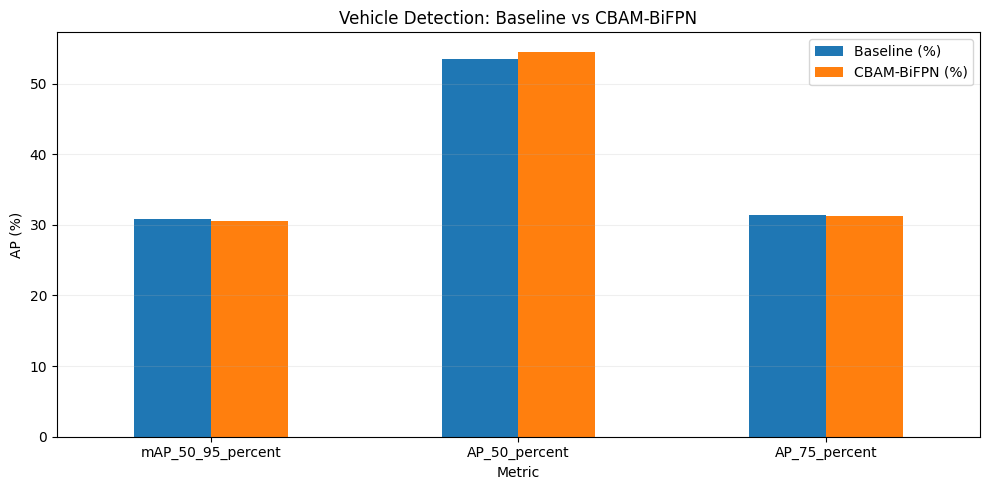

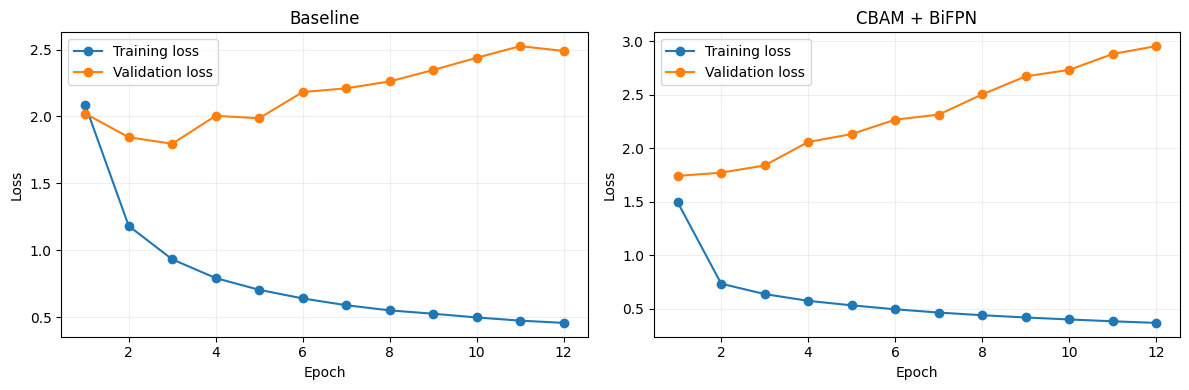


Saved comparison CSV and plots to Google Drive.


In [16]:

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
METRICS_DIR = PROJECT_DIR / "metrics"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load recorded model evaluation results
with open(METRICS_DIR / "baseline_validation_metrics.json") as f:
    baseline = json.load(f)

with open(METRICS_DIR / "improved_validation_metrics.json") as f:
    improved = json.load(f)

metric_keys = [
    "mAP_50_95_percent",
    "AP_50_percent",
    "AP_75_percent",
    "AP_car_percent",
    "AP_van_percent",
    "AP_bus_percent",
    "AP_others_percent",
]

comparison = pd.DataFrame({
    "Metric": metric_keys,
    "Baseline (%)": [baseline.get(k) for k in metric_keys],
    "CBAM-BiFPN (%)": [improved.get(k) for k in metric_keys],
})

comparison["Change (pp)"] = (
    comparison["CBAM-BiFPN (%)"] - comparison["Baseline (%)"]
)

comparison.to_csv(
    METRICS_DIR / "baseline_vs_improved.csv",
    index=False
)

print(comparison.to_string(index=False))

# Plot detection metrics
plot_metrics = comparison.iloc[:3]

ax = plot_metrics.set_index("Metric")[
    ["Baseline (%)", "CBAM-BiFPN (%)"]
].plot(kind="bar", figsize=(10, 5), rot=0)

ax.set_ylabel("AP (%)")
ax.set_title("Vehicle Detection: Baseline vs CBAM-BiFPN")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "baseline_vs_improved_metrics.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# Plot training and validation loss history
baseline_history = pd.read_csv(
    METRICS_DIR / "training_history.csv"
)
improved_history = pd.read_csv(
    METRICS_DIR / "improved_training_history.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, history, name in [
    (axes[0], baseline_history, "Baseline"),
    (axes[1], improved_history, "CBAM + BiFPN")
]:
    ax.plot(
        history["epoch"], history["train_loss"],
        marker="o", label="Training loss"
    )
    ax.plot(
        history["epoch"], history["val_loss"],
        marker="o", label="Validation loss"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "training_loss_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

print("\nSaved comparison CSV and plots to Google Drive.")

In [17]:

from pathlib import Path
import zipfile
import hashlib
import json
from google.colab import drive, files

drive.mount("/content/drive")

PROJECT = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
EXPORT_DIR = PROJECT / "exports"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

BUNDLE = EXPORT_DIR / "VehicleDetection_Model_Backup.zip"

# Save the important artifacts without copying the full dataset.
wanted_files = [
    "checkpoints/centernet_best.pth",
    "checkpoints/centernet_latest.pth",
    "checkpoints/improved_best.pth",
    "checkpoints/improved_latest.pth",
    "metrics/training_history.csv",
    "metrics/improved_training_history.csv",
    "metrics/baseline_validation_metrics.json",
    "metrics/improved_validation_metrics.json",
    "metrics/baseline_vs_improved.csv",
    "outputs/baseline_prediction_preview.png",
    "outputs/baseline_vs_improved_metrics.png",
    "outputs/training_loss_comparison.png",
    "outputs/validation_predictions.json",
    "outputs/improved_validation_predictions.json",
]

included = []
missing = []

with zipfile.ZipFile(
    BUNDLE, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for relative in wanted_files:
        path = PROJECT / relative
        if path.is_file():
            archive.write(path, arcname=relative)
            included.append(relative)
        else:
            missing.append(relative)

    # Include an inventory and the current metric comparison.
    inventory = {
        "project": "Improved CenterNet Vehicle Detection",
        "classes": ["car", "van", "bus", "others"],
        "input_size": [512, 288],
        "output_stride": 4,
        "included_files": included,
        "missing_files": missing,
        "note": (
            "Keep the original Google Drive checkpoints. "
            "The improved architecture source and exact "
            "preprocessing/inference code must also be retained "
            "for model loading."
        )
    }
    archive.writestr(
        "BACKUP_MANIFEST.json",
        json.dumps(inventory, indent=2)
    )

# Generate checksum for integrity verification.
digest = hashlib.sha256(BUNDLE.read_bytes()).hexdigest()
(BUNDLE.with_suffix(".sha256")).write_text(
    f"{digest}  {BUNDLE.name}\n"
)

print("Backup created:", BUNDLE)
print("Size (MB):", round(BUNDLE.stat().st_size / 1e6, 2))
print("Included files:", len(included))
print("Missing optional files:", missing)
print("SHA-256:", digest)

# Download the archive to your computer.
files.download(str(BUNDLE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backup created: /content/drive/MyDrive/VehicleDetectionProject/exports/VehicleDetection_Model_Backup.zip
Size (MB): 392.75
Included files: 14
Missing optional files: []
SHA-256: d96c1b806f249cd770ff0e19c9c6c985637214280e395f67d5a4476ad95889ae


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

import json, csv, random
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
from PIL import Image, ImageOps, ImageEnhance
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from tqdm.auto import tqdm

# ---------- Paths ----------
PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
ROOT = Path(DATASET_PATH)
IMAGE_ROOT = ROOT / "DETRAC-Images" / "DETRAC-Images"
ANN_DIR = PROJECT_DIR / "annotations"
CKPT_DIR = PROJECT_DIR / "checkpoints"
METRICS_DIR = PROJECT_DIR / "metrics"

for p in [CKPT_DIR, METRICS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

BASE_IMPROVED = CKPT_DIR / "improved_best.pth"
LATEST = CKPT_DIR / "improved_v2_latest.pth"
BEST = CKPT_DIR / "improved_v2_best.pth"
HISTORY_CSV = METRICS_DIR / "improved_v2_history.csv"
EPOCH_DIR = CKPT_DIR / "improved_v2_epochs"
EPOCH_DIR.mkdir(parents=True, exist_ok=True)

assert BASE_IMPROVED.exists(), "Existing improved checkpoint is missing."
assert (ANN_DIR / "train.json").exists()
assert (ANN_DIR / "val.json").exists()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

INPUT_W, INPUT_H = 512, 288
OUT_W, OUT_H = 128, 72
NUM_CLASSES = 4
MAX_OBJECTS = 100

# ---------- Dataset with training-only augmentation ----------
class DETRACDatasetV2(Dataset):
    def __init__(self, json_path, augment=False):
        with open(json_path) as f:
            self.data = json.load(f)

        self.images = self.data["images"]
        self.augment = augment
        self.anns = defaultdict(list)

        for a in self.data["annotations"]:
            self.anns[a["image_id"]].append(a)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        info = self.images[idx]
        image = Image.open(
            IMAGE_ROOT / info["file_name"]
        ).convert("RGB")
        image = image.resize(
            (INPUT_W, INPUT_H), Image.Resampling.BILINEAR
        )

        flip = self.augment and random.random() < 0.5
        if flip:
            image = ImageOps.mirror(image)

        if self.augment:
            image = ImageEnhance.Brightness(image).enhance(
                random.uniform(0.85, 1.15)
            )
            image = ImageEnhance.Contrast(image).enhance(
                random.uniform(0.85, 1.15)
            )

        arr = np.asarray(image, dtype=np.float32) / 255.0
        img = torch.from_numpy(arr.copy()).permute(2, 0, 1)

        mean = torch.tensor(
            [0.485, 0.456, 0.406]
        )[:, None, None]
        std = torch.tensor(
            [0.229, 0.224, 0.225]
        )[:, None, None]
        img = (img - mean) / std

        hm = np.zeros(
            (NUM_CLASSES, OUT_H, OUT_W), dtype=np.float32
        )
        wh = np.zeros((MAX_OBJECTS, 2), dtype=np.float32)
        off = np.zeros((MAX_OBJECTS, 2), dtype=np.float32)
        ind = np.zeros(MAX_OBJECTS, dtype=np.int64)
        mask = np.zeros(MAX_OBJECTS, dtype=np.uint8)

        sx, sy = INPUT_W / info["width"], INPUT_H / info["height"]
        n = 0

        for a in self.anns.get(info["id"], []):
            if n >= MAX_OBJECTS:
                break

            x, y, w, h = map(float, a["bbox"])
            x, w = x * sx, w * sx
            y, h = y * sy, h * sy

            if flip:
                x = INPUT_W - (x + w)

            cx, cy = (x + w / 2) / 4, (y + h / 2) / 4
            ix, iy = int(cx), int(cy)
            cls = int(a["category_id"]) - 1

            if not (0 <= cls < NUM_CLASSES and
                    0 <= ix < OUT_W and 0 <= iy < OUT_H and
                    w > 0 and h > 0):
                continue

            # CenterNet-style Gaussian center target
            radius, sigma = 2, 5 / 6
            x1, x2 = max(0, ix-radius), min(OUT_W-1, ix+radius)
            y1, y2 = max(0, iy-radius), min(OUT_H-1, iy+radius)

            xs = np.arange(x1, x2+1)
            ys = np.arange(y1, y2+1)
            xx, yy = np.meshgrid(xs, ys)
            g = np.exp(
                -((xx-ix)**2 + (yy-iy)**2)/(2*sigma*sigma)
            ).astype(np.float32)
            np.maximum(hm[cls, y1:y2+1, x1:x2+1], g,
                       out=hm[cls, y1:y2+1, x1:x2+1])

            wh[n] = [w/4, h/4]
            off[n] = [cx-ix, cy-iy]
            ind[n] = iy * OUT_W + ix
            mask[n] = 1
            n += 1

        return (
            img, torch.from_numpy(hm), torch.from_numpy(wh),
            torch.from_numpy(off), torch.from_numpy(ind),
            torch.from_numpy(mask)
        )


train_v2 = DETRACDatasetV2(ANN_DIR / "train.json", augment=True)
val_v2 = DETRACDatasetV2(ANN_DIR / "val.json", augment=False)

# Moderate class-aware image sampling based on class presence.
# It increases exposure to rare classes without altering validation data.
class_images = defaultdict(set)
with open(ANN_DIR / "train.json") as f:
    train_meta = json.load(f)

for ann in train_meta["annotations"]:
    class_images[ann["category_id"]].add(ann["image_id"])

class_freq = {
    c: max(1, len(ids)) for c, ids in class_images.items()
}

image_weights = []
for info in train_v2.images:
    present = {
        a["category_id"]
        for a in train_v2.anns.get(info["id"], [])
    }
    w = (
        max(1 / np.sqrt(class_freq[c]) for c in present)
        if present else 1.0
    )
    image_weights.append(float(w))

image_weights = torch.tensor(image_weights, dtype=torch.double)
image_weights /= image_weights.mean()
image_weights.clamp_(max=3.0)

sampler = WeightedRandomSampler(
    image_weights,
    num_samples=len(train_v2),
    replacement=True
)

train_loader_v2 = DataLoader(
    train_v2, batch_size=8 if use_amp else 2,
    sampler=sampler, num_workers=0, pin_memory=use_amp
)
val_loader_v2 = DataLoader(
    val_v2, batch_size=8 if use_amp else 2,
    shuffle=False, num_workers=0, pin_memory=use_amp
)

# ---------- Start from existing CBAM-BiFPN weights ----------
v2_model = ImprovedCenterNet(num_classes=4).to(device)

v2_model.load_state_dict(torch.load(
    BASE_IMPROVED, map_location=device, weights_only=True
))

optimizer = torch.optim.AdamW([
    {"params": v2_model.backbone.parameters(), "lr": 5e-6},
    {"params": v2_model.projections.parameters(), "lr": 2e-5},
    {"params": v2_model.attention.parameters(), "lr": 2e-5},
    {"params": v2_model.bifpn.parameters(), "lr": 2e-5},
    {"params": v2_model.hm_head.parameters(), "lr": 2e-5},
    {"params": v2_model.wh_head.parameters(), "lr": 2e-5},
    {"params": v2_model.off_head.parameters(), "lr": 2e-5},
], weight_decay=1e-3)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=1
)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

# ---------- Resume only a V2 checkpoint, if one exists ----------
start_epoch, history = 0, []
best_val = float("inf")
bad_epochs = 0
PATIENCE = 4
EPOCHS = 12

if LATEST.exists():
    state = torch.load(LATEST, map_location=device, weights_only=False)
    v2_model.load_state_dict(state["model_state_dict"])
    optimizer.load_state_dict(state["optimizer_state_dict"])
    scheduler.load_state_dict(state["scheduler_state_dict"])
    scaler.load_state_dict(state["scaler_state_dict"])
    start_epoch = state["epoch_completed"]
    history = state.get("history", [])
    best_val = state.get("best_val_loss", float("inf"))
    bad_epochs = state.get("bad_epochs", 0)
    print("Resuming V2 after epoch", start_epoch)
else:
    print("Starting V2 fine-tuning from improved_best.pth")

# ---------- Train with early stopping ----------
for epoch in range(start_epoch, EPOCHS):
    v2_model.train()
    train_sum = 0.0

    for batch in tqdm(train_loader_v2, desc=f"V2 Epoch {epoch+1}/{EPOCHS}"):
        batch = tuple(t.to(device, non_blocking=True) for t in batch)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=use_amp):
            outputs = v2_model(batch[0])

        losses = compute_centernet_loss(outputs, batch)
        loss = losses["total"]

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss.")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(v2_model.parameters(), 5.0)
        scaler.step(optimizer)
        scaler.update()
        train_sum += loss.item()

    train_avg = train_sum / max(1, len(train_loader_v2))

    v2_model.eval()
    val_sum = 0.0

    with torch.inference_mode():
        for batch in tqdm(val_loader_v2, desc="V2 validation"):
            batch = tuple(t.to(device, non_blocking=True) for t in batch)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                outputs = v2_model(batch[0])
            val_sum += compute_centernet_loss(outputs, batch)["total"].item()

    val_avg = val_sum / max(1, len(val_loader_v2))
    scheduler.step(val_avg)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_avg,
        "val_loss": val_avg
    })

    improved = val_avg < best_val - 1e-4
    if improved:
        best_val = val_avg
        bad_epochs = 0
        torch.save(v2_model.state_dict(), BEST)
    else:
        bad_epochs += 1

    # Save an epoch-specific weights file for later metric comparison.
    epoch_path = EPOCH_DIR / f"epoch_{epoch+1:02d}.pth"
    torch.save(v2_model.state_dict(), epoch_path)

    torch.save({
        "epoch_completed": epoch + 1,
        "model_state_dict": v2_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "best_val_loss": best_val,
        "bad_epochs": bad_epochs
    }, LATEST)

    with open(HISTORY_CSV, "w", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=["epoch", "train_loss", "val_loss"]
        )
        writer.writeheader()
        writer.writerows(history)

    print(
        f"V2 Epoch {epoch+1}: train={train_avg:.4f}, "
        f"val={val_avg:.4f}, best_val={best_val:.4f}"
    )

    if bad_epochs >= PATIENCE:
        print("Early stopping: validation loss did not improve.")
        break

print("\nV2 training finished.")
print("Best weights:", BEST)
print("Latest recovery checkpoint:", LATEST)
print("Epoch weights:", EPOCH_DIR)
print("History:", HISTORY_CSV)

Starting V2 fine-tuning from improved_best.pth


V2 Epoch 1/12:   0%|          | 0/852 [00:00<?, ?it/s]

V2 validation:   0%|          | 0/178 [00:00<?, ?it/s]

V2 Epoch 1: train=1.0810, val=1.5602, best_val=1.5602


V2 Epoch 2/12:   0%|          | 0/852 [00:00<?, ?it/s]

...

V2 validation:   0%|          | 0/178 [00:00<?, ?it/s]

V2 Epoch 4: train=0.8410, val=1.6276, best_val=1.5602


V2 Epoch 5/12:   0%|          | 0/852 [00:00<?, ?it/s]

V2 validation:   0%|          | 0/178 [00:00<?, ?it/s]

V2 Epoch 5: train=0.8169, val=1.6035, best_val=1.5602
Early stopping: validation loss did not improve.

V2 training finished.
Best weights: /content/drive/MyDrive/VehicleDetectionProject/checkpoints/improved_v2_best.pth
Latest recovery checkpoint: /content/drive/MyDrive/VehicleDetectionProject/checkpoints/improved_v2_latest.pth
Epoch weights: /content/drive/MyDrive/VehicleDetectionProject/checkpoints/improved_v2_epochs
History: /content/drive/MyDrive/VehicleDetectionProject/metrics/improved_v2_history.csv


In [19]:
from pathlib import Path
import torch
import json

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
METRICS_DIR = PROJECT_DIR / "metrics"
OUTPUT_DIR = PROJECT_DIR / "outputs"

for folder in [CHECKPOINT_DIR, METRICS_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("V2 checkpoint exists:",
      (CHECKPOINT_DIR / "improved_v2_best.pth").exists())

print("Baseline checkpoint exists:",
      (CHECKPOINT_DIR / "centernet_best.pth").exists())

print("Improved checkpoint exists:",
      (CHECKPOINT_DIR / "improved_best.pth").exists())

print("CUDA available:", torch.cuda.is_available())

V2 checkpoint exists: True
Baseline checkpoint exists: True
Improved checkpoint exists: True
CUDA available: True


In [20]:
from pathlib import Path
import json

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)

files = [
    PROJECT_DIR / "annotations" / "val.json",
    PROJECT_DIR / "metrics" / "baseline_validation_metrics.json",
    PROJECT_DIR / "metrics" / "improved_validation_metrics.json",
    PROJECT_DIR / "checkpoints" / "improved_v2_best.pth",
]

for path in files:
    print(f"{'OK' if path.exists() else 'MISSING'}: {path.name}")

# Display the existing comparison metrics
for name in [
    "baseline_validation_metrics.json",
    "improved_validation_metrics.json",
]:
    path = PROJECT_DIR / "metrics" / name
    if path.exists():
        with open(path) as f:
            metrics = json.load(f)
        print(f"\n{name}")
        print(json.dumps(metrics, indent=2)[:2500])

OK: val.json
OK: baseline_validation_metrics.json
OK: improved_validation_metrics.json
OK: improved_v2_best.pth

baseline_validation_metrics.json
{
  "images_evaluated": 1417,
  "predicted_boxes": 141700,
  "mAP_50_95_percent": 30.87,
  "AP_50_percent": 53.42,
  "AP_75_percent": 31.36,
  "AR_100_percent": 53.25,
  "AP_car_percent": 42.89,
  "AP_van_percent": 32.43,
  "AP_bus_percent": 44.55,
  "AP_others_percent": 3.6
}

improved_validation_metrics.json
{
  "images_evaluated": 1417,
  "predicted_boxes": 141700,
  "mAP_50_95_percent": 30.49,
  "AP_50_percent": 54.52,
  "AP_75_percent": 31.22,
  "AP_car_percent": 46.22,
  "AP_van_percent": 34.56,
  "AP_bus_percent": 38.5,
  "AP_others_percent": 2.67
}


In [21]:
import inspect

keywords = (
    "centernet", "evaluate", "coco", "predict",
    "decode", "validation", "inference", "dataset"
)

for name, obj in list(globals().items()):
    if any(k in name.lower() for k in keywords):
        if inspect.isclass(obj) or inspect.isfunction(obj):
            print(f"{name}: {type(obj).__name__}")

Dataset: type
DETRACDataset: type
CenterNetBaseline: type
compute_centernet_loss: function
COCO: type
COCOeval: type
ImprovedCenterNet: type
DETRACDatasetV2: type


In [22]:
from pathlib import Path
import torch

checkpoint_path = Path(
    "/content/drive/MyDrive/VehicleDetectionProject/"
    "checkpoints/improved_v2_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"\n{key}: dictionary with {len(value)} entries")
            print("Sample keys:", list(value.keys())[:8])
        elif isinstance(value, (int, float, str, bool)):
            print(f"{key}: {value}")
        else:
            print(f"{key}: {type(value).__name__}")

Checkpoint type: OrderedDict
Checkpoint keys: ['backbone.conv1.weight', 'backbone.bn1.weight', 'backbone.bn1.bias', 'backbone.bn1.running_mean', 'backbone.bn1.running_var', 'backbone.bn1.num_batches_tracked', 'backbone.layer1.0.conv1.weight', 'backbone.layer1.0.bn1.weight', 'backbone.layer1.0.bn1.bias', 'backbone.layer1.0.bn1.running_mean', 'backbone.layer1.0.bn1.running_var', 'backbone.layer1.0.bn1.num_batches_tracked', 'backbone.layer1.0.conv2.weight', 'backbone.layer1.0.bn2.weight', 'backbone.layer1.0.bn2.bias', 'backbone.layer1.0.bn2.running_mean', 'backbone.layer1.0.bn2.running_var', 'backbone.layer1.0.bn2.num_batches_tracked', 'backbone.layer1.1.conv1.weight', 'backbone.layer1.1.bn1.weight', 'backbone.layer1.1.bn1.bias', 'backbone.layer1.1.bn1.running_mean', 'backbone.layer1.1.bn1.running_var', 'backbone.layer1.1.bn1.num_batches_tracked', 'backbone.layer1.1.conv2.weight', 'backbone.layer1.1.bn2.weight', 'backbone.layer1.1.bn2.bias', 'backbone.layer1.1.bn2.running_mean', 'backbone

In [23]:
import inspect

print("=== ImprovedCenterNet constructor ===")
print(inspect.signature(ImprovedCenterNet))

print("\n=== Validation dataset constructor ===")
print(inspect.signature(DETRACDatasetV2))

print("\n=== Baseline dataset constructor ===")
print(inspect.signature(DETRACDataset))

print("\n=== Relevant existing variables ===")
for name in [
    "val_dataset", "val_loader", "val_dataloader",
    "val_json", "device", "IMG_SIZE",
    "NUM_CLASSES", "CLASS_NAMES"
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: {type(value).__name__}", end="")
        if isinstance(value, (str, int, float, tuple, list)):
            print(f" = {str(value)[:200]}")
        else:
            print()

=== ImprovedCenterNet constructor ===
(num_classes=4)

=== Validation dataset constructor ===
(json_path, augment=False)

=== Baseline dataset constructor ===
(json_path)

=== Relevant existing variables ===
val_loader: DataLoader
val_json: dict
device: device
NUM_CLASSES: int = 4
CLASS_NAMES: list = ['car', 'van', 'bus', 'others']


In [24]:
import torch
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
checkpoint_path = (
    PROJECT_DIR / "checkpoints" / "improved_v2_best.pth"
)

# Load V2 weights
model_v2 = ImprovedCenterNet(num_classes=NUM_CLASSES).to(device)

state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
model_v2.load_state_dict(state_dict, strict=True)
model_v2.eval()

print("V2 checkpoint loaded successfully!")
print("Classes:", CLASS_NAMES)


def inspect_output(obj, name="output"):
    if torch.is_tensor(obj):
        print(
            f"{name}: Tensor shape={tuple(obj.shape)}, "
            f"dtype={obj.dtype}"
        )
    elif isinstance(obj, dict):
        print(f"{name}: dict keys={list(obj.keys())}")
        for key, value in obj.items():
            inspect_output(value, f"{name}[{key!r}]")
    elif isinstance(obj, (tuple, list)):
        print(f"{name}: {type(obj).__name__}, length={len(obj)}")
        for i, value in enumerate(obj[:6]):
            inspect_output(value, f"{name}[{i}]")
    else:
        print(f"{name}: {type(obj).__name__}")


# Inspect one validation batch
batch = next(iter(val_loader))
print("\n=== Validation batch structure ===")
inspect_output(batch, "batch")


def find_image_tensor(obj):
    if torch.is_tensor(obj) and obj.ndim == 4:
        if obj.shape[1] == 3:
            return obj
    if isinstance(obj, dict):
        for value in obj.values():
            result = find_image_tensor(value)
            if result is not None:
                return result
    if isinstance(obj, (tuple, list)):
        for value in obj:
            result = find_image_tensor(value)
            if result is not None:
                return result
    return None


images = find_image_tensor(batch)

if images is None:
    print("\nCould not automatically identify the image tensor.")
else:
    print("\n=== V2 prediction structure ===")
    with torch.inference_mode():
        predictions = model_v2(images[:1].to(device))
    inspect_output(predictions, "predictions")

V2 checkpoint loaded successfully!
Classes: ['car', 'van', 'bus', 'others']

=== Validation batch structure ===
batch: list, length=6
batch[0]: Tensor shape=(8, 3, 288, 512), dtype=torch.float32
batch[1]: Tensor shape=(8, 4, 72, 128), dtype=torch.float32
batch[2]: Tensor shape=(8, 100, 2), dtype=torch.float32
batch[3]: Tensor shape=(8, 100, 2), dtype=torch.float32
batch[4]: Tensor shape=(8, 100), dtype=torch.int64
batch[5]: Tensor shape=(8, 100), dtype=torch.uint8

=== V2 prediction structure ===
predictions: dict keys=['hm', 'wh', 'off']
predictions['hm']: Tensor shape=(1, 4, 72, 128), dtype=torch.float32
predictions['wh']: Tensor shape=(1, 2, 72, 128), dtype=torch.float32
predictions['off']: Tensor shape=(1, 2, 72, 128), dtype=torch.float32


In [27]:
import json
import numpy as np
import torch
import torch.nn.functional as F

from pathlib import Path
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# -------------------- 1. PATHS --------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)

VAL_PATH = PROJECT_DIR / "annotations" / "val.json"
CHECKPOINT_PATH = (
    PROJECT_DIR / "checkpoints" / "improved_v2_best.pth"
)

METRICS_DIR = PROJECT_DIR / "metrics"
OUTPUT_DIR = PROJECT_DIR / "outputs"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert VAL_PATH.exists(), f"Missing validation JSON: {VAL_PATH}"
assert CHECKPOINT_PATH.exists(), (
    f"Missing V2 checkpoint: {CHECKPOINT_PATH}"
)

# -------------------- 2. CONFIGURATION --------------------

CLASS_NAMES = ["car", "van", "bus", "others"]
NUM_CLASSES = 4

INPUT_W = 512
INPUT_H = 288
OUTPUT_STRIDE = 4  # Correct variable name
TOPK = 100
SCORE_THRESHOLD = 0.001

# -------------------- 3. LOAD ANNOTATIONS --------------------

with open(VAL_PATH, "r") as f:
    val_data = json.load(f)

image_records = val_data["images"]
categories = val_data["categories"]

category_id_by_name = {
    category["name"].lower(): int(category["id"])
    for category in categories
}

assert len(image_records) == len(val_loader.dataset), (
    f"Image count mismatch: JSON has {len(image_records)} images, "
    f"dataset has {len(val_loader.dataset)}"
)

assert all(
    name in category_id_by_name for name in CLASS_NAMES
), f"Class mismatch: {category_id_by_name}"

category_ids = [
    category_id_by_name[name] for name in CLASS_NAMES
]

print("Validation images:", len(image_records))
print("Classes:", CLASS_NAMES)

# Keep validation order deterministic.
eval_loader = DataLoader(
    val_loader.dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# -------------------- 4. LOAD V2 CHECKPOINT --------------------

model_v2 = ImprovedCenterNet(
    num_classes=NUM_CLASSES
).to(device)

state_dict = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

model_v2.load_state_dict(state_dict, strict=True)
model_v2.eval()

print("V2 checkpoint loaded successfully.")
print("Device:", device)

# -------------------- 5. RUN INFERENCE --------------------

predictions = []
image_position = 0

with torch.inference_mode():
    for batch in tqdm(eval_loader, desc="Evaluating V2"):

        # Dataset batch:
        # images, heatmaps, widths/heights, offsets, indices, masks
        images = batch[0].to(device, non_blocking=True)

        outputs = model_v2(images)

        # Detection head outputs
        hm = outputs["hm"].sigmoid()
        wh = outputs["wh"]
        off = outputs["off"]

        # Keep local heatmap maxima.
        pooled = F.max_pool2d(
            hm, kernel_size=3, stride=1, padding=1
        )
        hm = hm * (hm == pooled).to(hm.dtype)

        batch_size, num_classes, out_h, out_w = hm.shape

        if num_classes != NUM_CLASSES:
            raise ValueError(
                f"Expected {NUM_CLASSES} classes, got {num_classes}"
            )

        # Select top detections across all classes.
        k = min(TOPK, num_classes * out_h * out_w)

        scores_flat = hm.reshape(batch_size, -1)
        top_scores, top_indices = torch.topk(
            scores_flat, k=k, dim=1
        )

        spatial_indices = top_indices % (out_h * out_w)
        class_indices = top_indices // (out_h * out_w)

        ys = (spatial_indices // out_w).float()
        xs = (spatial_indices % out_w).float()

        # Rearrange width/height and offset heads for gathering.
        wh_flat = wh.permute(0, 2, 3, 1).reshape(
            batch_size, -1, 2
        )
        off_flat = off.permute(0, 2, 3, 1).reshape(
            batch_size, -1, 2
        )

        gather_indices = spatial_indices.unsqueeze(-1).expand(
            -1, -1, 2
        )

        wh_pred = wh_flat.gather(1, gather_indices)
        off_pred = off_flat.gather(1, gather_indices)

        # IMPORTANT: use OUTPUT_STRIDE consistently.
        centers_x = (
            xs + off_pred[..., 0]
        ) * OUTPUT_STRIDE

        centers_y = (
            ys + off_pred[..., 1]
        ) * OUTPUT_STRIDE

        widths = wh_pred[..., 0].clamp(min=0) * OUTPUT_STRIDE
        heights = wh_pred[..., 1].clamp(min=0) * OUTPUT_STRIDE

        x1 = centers_x - widths / 2
        y1 = centers_y - heights / 2
        x2 = centers_x + widths / 2
        y2 = centers_y + heights / 2

        scores_np = top_scores.cpu().numpy()
        classes_np = class_indices.cpu().numpy()

        boxes_np = torch.stack(
            [x1, y1, x2, y2], dim=-1
        ).cpu().numpy()

        # Convert every image's predictions to COCO format.
        for b in range(batch_size):

            if image_position >= len(image_records):
                raise RuntimeError(
                    "Processed more images than the validation JSON."
                )

            meta = image_records[image_position]
            image_position += 1

            image_id = int(meta["id"])
            original_w = float(meta["width"])
            original_h = float(meta["height"])

            scale_x = original_w / INPUT_W
            scale_y = original_h / INPUT_H

            for j in range(k):

                score = float(scores_np[b, j])

                if score < SCORE_THRESHOLD:
                    continue

                class_idx = int(classes_np[b, j])

                bx1, by1, bx2, by2 = boxes_np[b, j]

                # Resize coordinates back to original image dimensions.
                bx1 *= scale_x
                bx2 *= scale_x
                by1 *= scale_y
                by2 *= scale_y

                bx1 = float(np.clip(bx1, 0, original_w))
                bx2 = float(np.clip(bx2, 0, original_w))
                by1 = float(np.clip(by1, 0, original_h))
                by2 = float(np.clip(by2, 0, original_h))

                box_w = bx2 - bx1
                box_h = by2 - by1

                if not np.isfinite(
                    [bx1, by1, box_w, box_h, score]
                ).all():
                    continue

                if box_w <= 0 or box_h <= 0:
                    continue

                predictions.append({
                    "image_id": image_id,
                    "category_id": category_ids[class_idx],
                    "bbox": [
                        round(bx1, 3),
                        round(by1, 3),
                        round(box_w, 3),
                        round(box_h, 3)
                    ],
                    "score": score
                })

assert image_position == len(image_records), (
    f"Processed {image_position} of "
    f"{len(image_records)} validation images."
)

# -------------------- 6. SAVE PREDICTIONS --------------------

pred_path = (
    OUTPUT_DIR / "improved_v2_validation_predictions.json"
)

with open(pred_path, "w") as f:
    json.dump(predictions, f)

print("\nImages evaluated:", image_position)
print("Predicted boxes:", len(predictions))
print("Predictions saved to:", pred_path)

# -------------------- 7. COCO EVALUATION --------------------

coco_gt = COCO(str(VAL_PATH))

if predictions:
    coco_dt = coco_gt.loadRes(str(pred_path))
else:
    raise RuntimeError(
        "V2 produced no detections. Check the checkpoint, "
        "preprocessing and score threshold before evaluating."
    )

evaluator = COCOeval(coco_gt, coco_dt, "bbox")

evaluator.params.imgIds = [
    int(item["id"]) for item in image_records
]
evaluator.params.catIds = sorted(category_ids)
evaluator.params.maxDets = [1, 10, 100]

evaluator.evaluate()
evaluator.accumulate()
evaluator.summarize()

stats = evaluator.stats

# -------------------- 8. COLLECT METRICS --------------------

metrics = {
    "images_evaluated": image_position,
    "predicted_boxes": len(predictions),
    "mAP_50_95_percent": round(float(stats[0] * 100), 2),
    "AP_50_percent": round(float(stats[1] * 100), 2),
    "AP_75_percent": round(float(stats[2] * 100), 2),
    "AP_small_percent": round(float(stats[3] * 100), 2),
    "AP_medium_percent": round(float(stats[4] * 100), 2),
    "AP_large_percent": round(float(stats[5] * 100), 2),
    "AR_100_percent": round(float(stats[8] * 100), 2)
}

# Per-class AP across IoU thresholds and recall points.
precision = evaluator.eval["precision"]
eval_category_ids = evaluator.params.catIds

for class_index, category_id in enumerate(eval_category_ids):

    category_name = next(
        category["name"].lower()
        for category in categories
        if int(category["id"]) == int(category_id)
    )

    class_precision = precision[:, :, class_index, 0, -1]
    valid_precision = class_precision[class_precision > -1]

    metrics[f"AP_{category_name}_percent"] = (
        round(float(valid_precision.mean() * 100), 2)
        if valid_precision.size
        else None
    )

# -------------------- 9. SAVE RESULTS --------------------

metrics_path = (
    METRICS_DIR / "improved_v2_validation_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print("\n" + "=" * 45)
print("       V2 VALIDATION RESULTS")
print("=" * 45)
print(json.dumps(metrics, indent=2))
print("\nMetrics saved to:", metrics_path)
print("Evaluation complete — no model training performed.")

Validation images: 1417
Classes: ['car', 'van', 'bus', 'others']
V2 checkpoint loaded successfully.
Device: cuda


Evaluating V2:   0%|          | 0/178 [00:00<?, ?it/s]


Images evaluated: 1417
Predicted boxes: 141700
Predictions saved to: /content/drive/MyDrive/VehicleDetectionProject/outputs/improved_v2_validation_predictions.json
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
Loading and preparing results...
DONE (t=1.24s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=8.60s).
Accumulating evaluation results...
DONE (t=1.47s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.336
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.589
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.341
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.060
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.314
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.455
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | ma

In [29]:
from IPython import get_ipython
import json
from pathlib import Path

ip = get_ipython()
history = ip.user_ns.get("In", [])

# Recover class definitions from cells previously run in Colab.
targets = [
    "DETRACDatasetV2",
    "ImprovedCenterNet",
    "DETRACDataset",
]

for name in targets:
    matches = [
        (i, cell)
        for i, cell in enumerate(history)
        if f"class {name}" in cell
    ]

    print("\n" + "=" * 70)
    print(f"CLASS: {name}")
    print("=" * 70)

    if matches:
        cell_number, source = matches[-1]
        print(f"Recovered from notebook input cell {cell_number}")
        print(source)
    else:
        print("Definition not found in notebook input history.")

# Inspect the existing sequence split without changing it.
project_dir = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
manifest_path = project_dir / "configs" / "split_manifest.json"

print("\n" + "=" * 70)
print("CURRENT SPLIT MANIFEST")
print("=" * 70)

if manifest_path.exists():
    with open(manifest_path, "r") as f:
        print(json.dumps(json.load(f), indent=2))
else:
    print("Manifest not found:", manifest_path)


CLASS: DETRACDatasetV2
Recovered from notebook input cell 18
import json, csv, random
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
from PIL import Image, ImageOps, ImageEnhance
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from tqdm.auto import tqdm

# ---------- Paths ----------
PROJECT_DIR = Path(
    "/content/drive/MyDrive/VehicleDetectionProject"
)
ROOT = Path(DATASET_PATH)
IMAGE_ROOT = ROOT / "DETRAC-Images" / "DETRAC-Images"
ANN_DIR = PROJECT_DIR / "annotations"
CKPT_DIR = PROJECT_DIR / "checkpoints"
METRICS_DIR = PROJECT_DIR / "metrics"

for p in [CKPT_DIR, METRICS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

BASE_IMPROVED = CKPT_DIR / "improved_best.pth"
LATEST = CKPT_DIR / "improved_v2_latest.pth"
BEST = CKPT_DIR / "improved_v2_best.pth"
HISTORY_CSV = METRICS_DIR / "improved_v2_history.csv"
EPOCH_DIR = CKPT_DIR / "improved_v2_epochs"
EPOCH_DIR.mkdir(parents=True, exist_ok=True)

assert BASE_IMPROVE

In [31]:
from pathlib import Path
from google.colab import files

model_path = Path(
    "/content/drive/MyDrive/VehicleDetectionProject/"
    "checkpoints/improved_v2_best.pth"
)

assert model_path.exists(), "V2 checkpoint not found!"

print(f"Model size: {model_path.stat().st_size / (1024 * 1024):.1f} MB")
files.download(str(model_path))

Model size: 45.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>